# Assignment: Amazon Sales Dataset — EDA, Feature Engineering & Basic Modeling

**Dataset:** [Amazon Sales Dataset on Kaggle](https://www.kaggle.com/datasets/karkavelrajaj/amazon-sales-dataset) — file `amazon.csv` (~1,465 rows, 16 columns).

**Total marks:** 100 (+10 bonus) · **Estimated effort:** 8–10 hours

**Instructions**
- Answer every question in the cells provided. Add more cells if you need them.
- Every plot needs a title, labelled axes (with units) and 1–2 sentences of interpretation below it.
- Use `random_state=42` wherever randomness is involved.
- The notebook must run top-to-bottom without errors before submission.
- Disclose any AI-tool use in the final cell.

**Name:** Nicole Akinyi Otieno · **Roll no.:** 1020231428

## Setup
Import the libraries you need and list their versions.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Add further imports here (scikit-learn, nltk/textblob, etc.)


## Dataset columns

| Column | Meaning | Raw format / notes |
| --- | --- | --- |
| product_id | Amazon ASIN | String; some IDs repeat |
| product_name | Listing title | Free text |
| category | Category path | Pipe-separated (`\|`) |
| discounted_price | Selling price (₹) | String with `₹` and commas |
| actual_price | List price (₹) | String with `₹` and commas |
| discount_percentage | Discount | String like `64%` |
| rating | Average star rating | String; contains an invalid value |
| rating_count | Number of ratings | String with commas; a few missing |
| about_product | Product description | Free text |
| user_id, user_name | Reviewers | Comma-separated lists |
| review_id, review_title, review_content | Reviews | Comma-separated lists |
| img_link, product_link | URLs | Not needed for modeling |

# Part A — Data loading and cleaning (15 marks)
Produce a clean DataFrame `df_clean` and justify every cleaning decision in a markdown cell.

**A1 (2 marks).** Load `amazon.csv` and report its shape, dtypes, `head()` and memory usage.

In [4]:
# Your code here
load_data = pd.read_csv(r'/Users/nkki/Downloads/amazon.csv') 
load_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

In [5]:
load_data.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


**A2 (3 marks).** Convert `discounted_price` and `actual_price` to floats by stripping `₹` and commas. Convert `discount_percentage` to a float between 0 and 1.

In [6]:
# Your code here
copy_load_data = load_data.copy()
copy_load_data['discounted_price'] = copy_load_data['discounted_price'].str[1:].str.replace(',', '').astype(float)
copy_load_data['actual_price'] = copy_load_data['actual_price'].str[1:].str.replace(',', '').astype(float)
copy_load_data['discount_percentage'] = copy_load_data['discount_percentage'].str.replace('%', '').astype(float) / 100

In [7]:
#copy_load_data.info()
copy_load_data.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,0.64,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,0.43,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,0.90,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,0.53,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,0.61,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


**A3 (2 marks).** Convert `rating` to float. Find the invalid value(s) and explain what you did with them (drop, impute or look up) and why.

In [8]:
#find number of values having 0
#copy_load_data['rating'].eq(0).sum()
#find number of values having | 
copy_load_data['rating'].eq('|').sum()
#find  the entire row where the rating is equal to |
copy_load_data[copy_load_data['rating'] == '|']


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
1279,B08L12N5H1,Eureka Forbes car Vac 100 Watts Powerful Sucti...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cle...",2099.0,2499.0,0.16,|,992,No Installation is provided for this product|1...,"AGTDSNT2FKVYEPDPXAA673AIS44A,AER2XFSWNN4LAUCJ5...","Divya,Dr Nefario,Deekshith,Preeti,Prasanth R,P...","R2KKTKM4M9RDVJ,R1O692MZOBTE79,R2WRSEWL56SOS4,R...","Decent product,doesn't pick up sand,Ok ok,Must...","Does the job well,doesn't work on sand. though...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Vacuum-Cle...


In [9]:
# Your code here
copy_load_data = copy_load_data[copy_load_data['rating'] != '|']
copy_load_data['rating'] = copy_load_data['rating'].astype(float)

**Your answer:**

While cleaning the `rating` column, one entry contained an invalid value (`|`) instead of a numeric rating. Two options were considered: dropping the row or imputing a value.

##### Why imputation was not used

A simple mean or median imputation would assign a generic "average" rating without regard to how that specific product was actually received. A more accurate imputation would require sentiment analysis of the product's review text to estimate a rating aligned with the actual review content, then use the mean rating of similar products — which adds significant complexity for a single affected row.

##### Decision: Row removed

Since only **one row** out of ~1465 was affected (roughly 0.07% of the dataset), the row was dropped rather than imputed. This avoids introducing an artificial or potentially misleading rating value while having negligible impact on the overall dataset size or distribution.

Removing this row ensures the `rating` column contains only genuine, valid numeric ratings, preserving the integrity of any rating-based statistics or analysis.

**A4 (2 marks).** Convert `rating_count` to integer. Report how many values are missing and choose a handling strategy.

In [10]:
# Your code here
copy_load_data['rating_count'].isnull().sum()
#find the number of values having 0
#copy_load_data['rating_count'].eq(0).sum()


np.int64(2)

In [11]:
#Drop null values and convert to int

copy_load_data = copy_load_data.dropna(subset=['rating_count']).reset_index(drop=True)
copy_load_data['rating_count'] = copy_load_data['rating_count'].astype(str).str.replace(',', '', regex=True).astype(int)
copy_load_data['rating_count'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1462 entries, 0 to 1461
Series name: rating_count
Non-Null Count  Dtype
--------------  -----
1462 non-null   int64
dtypes: int64(1)
memory usage: 11.5 KB


**Your answer:**

The `rating_count` column had **2 rows with null values**. Initially, these were imputed with `0`, but this was reconsidered.

##### Why 0 was not appropriate

`rating_count` represents the number of people who rated a product. A value of `0` implies *no ratings exist*, which contradicts rows that still have a valid `rating` value — a product cannot have an average rating with zero ratings behind it. Imputing `0` here would introduce a logically inconsistent value rather than represent genuinely missing data.

##### Decision: Rows removed

Since only 2 rows out of ~1465 were affected (about 0.14% of the dataset), the rows were dropped rather than imputed, avoiding an invented or contradictory value.

**A5 (3 marks).** Check for duplicates: full-row duplicates and repeated `product_id`s. Decide which rows to keep and state your rule.

In [12]:
# Your code here
#copy_load_data['product_id'].nunique()
copy_load_data.nunique()

product_id             1348
product_name           1334
category                211
discounted_price        550
actual_price            449
discount_percentage      92
rating                   25
rating_count           1142
about_product          1290
user_id                1191
user_name              1191
review_id              1191
review_title           1191
review_content         1209
img_link               1409
product_link           1462
dtype: int64

In [13]:
# IDs that map to more than one distinct name
id_multi_name = copy_load_data.groupby('product_id')['product_name'].nunique()
id_multi_name = id_multi_name[id_multi_name > 1].index
same_id_diff_name = copy_load_data[copy_load_data['product_id'].isin(id_multi_name)]

# names that map to more than one distinct ID
name_multi_id = copy_load_data.groupby('product_name')['product_id'].nunique()
name_multi_id = name_multi_id[name_multi_id > 1].index
same_name_diff_id = copy_load_data[copy_load_data['product_name'].isin(name_multi_id)]

print(len(same_id_diff_name), len(same_name_diff_id))
same_name_diff_id.sort_values('product_name')

0 26


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
363,B09YV4MW2T,Fire-Boltt India's No 1 Smartwatch Brand Talk ...,Electronics|WearableTechnology|SmartWatches,2199.0,9999.0,0.78,4.2,29471,【Bluetooth Calling Watch】- Fire-Boltt Talk 2 e...,"AEJQT5NMTAM2ZRPQDNGLOL6NTKRQ,AHIKFQ5VP6QGYQK3G...","Deepankar G.,Babu Singh Rathore,Liton Das,Bisw...","R26YAKWWPQSNL,R30L263BU0PTZP,R1A8G9G8J5Z3V5,RB...","Worth the price, expecting good performance on...",Received the product today. The packing was in...,https://m.media-amazon.com/images/I/41Mce3f9fa...,https://www.amazon.in/Fire-Boltt-Smartwatch-Bl...
482,B09YV3K34W,Fire-Boltt India's No 1 Smartwatch Brand Talk ...,Electronics|WearableTechnology|SmartWatches,2199.0,9999.0,0.78,4.2,29472,【Bluetooth Calling Watch】- Fire-Boltt Talk 2 s...,"AEJQT5NMTAM2ZRPQDNGLOL6NTKRQ,AHIKFQ5VP6QGYQK3G...","Deepankar G.,Babu Singh Rathore,Liton Das,Bisw...","R26YAKWWPQSNL,R30L263BU0PTZP,R1A8G9G8J5Z3V5,RB...","Worth the price, expecting good performance on...",Received the product today. The packing was in...,https://m.media-amazon.com/images/I/41vMaBVWDj...,https://www.amazon.in/Fire-Boltt-Smartwatch-Bl...
609,B09YV4MW2T,Fire-Boltt India's No 1 Smartwatch Brand Talk ...,Electronics|WearableTechnology|SmartWatches,2199.0,9999.0,0.78,4.2,29478,【Bluetooth Calling Watch】- Fire-Boltt Talk 2 e...,"AEJQT5NMTAM2ZRPQDNGLOL6NTKRQ,AHIKFQ5VP6QGYQK3G...","Deepankar G.,Babu Singh Rathore,Liton Das,Bisw...","R26YAKWWPQSNL,R30L263BU0PTZP,R1A8G9G8J5Z3V5,RB...","Worth the price, expecting good performance on...",Received the product today. The packing was in...,https://m.media-amazon.com/images/I/41Mce3f9fa...,https://www.amazon.in/Fire-Boltt-Smartwatch-Bl...
378,B0BF54LXW6,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Electronics|WearableTechnology|SmartWatches,1799.0,19999.0,0.91,4.2,13937,Fire-Boltt is India' No 1 Wearable Watch Brand...,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","venkatesh kg,Raghuram,YOGESH,Manan Parmar,Niku...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS...","Worth the money,Good smart watch,the screen do...","I liked it, worth the money, light weight and ...",https://m.media-amazon.com/images/I/41Fq27ZjJf...,https://www.amazon.in/Fire-Boltt-Bluetooth-Cal...
332,B0BF57RN3K,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Electronics|WearableTechnology|SmartWatches,1799.0,19999.0,0.91,4.2,13937,Fire-Boltt is India' No 1 Wearable Watch Brand...,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","venkatesh kg,Raghuram,YOGESH,Manan Parmar,Niku...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS...","Worth the money,Good smart watch,the screen do...","I liked it, worth the money, light weight and ...",https://m.media-amazon.com/images/I/41WCgGbvwh...,https://www.amazon.in/Fire-Boltt-Bluetooth-Cal...
362,B0BF54972T,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Electronics|WearableTechnology|SmartWatches,1799.0,19999.0,0.91,4.2,13937,Fire-Boltt is India' No 1 Wearable Watch Brand...,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","venkatesh kg,Raghuram,YOGESH,Manan Parmar,Niku...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS...","Worth the money,Good smart watch,the screen do...","I liked it, worth the money, light weight and ...",https://m.media-amazon.com/images/I/41mzbWC6Ak...,https://www.amazon.in/Fire-Boltt-Bluetooth-Cal...
366,B0BF563HB4,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Electronics|WearableTechnology|SmartWatches,1799.0,19999.0,0.91,4.2,13937,Fire-Boltt is India' No 1 Wearable Watch Brand...,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","venkatesh kg,Raghuram,YOGESH,Manan Parmar,Niku...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS...","Worth the money,Good smart watch,the screen do...","I liked it, worth the money, light weight and ...",https://m.media-amazon.com/images/I/41ivjqdXb0...,https://

In [14]:
before = len(copy_load_data)
deduped = copy_load_data.drop_duplicates(subset=['product_id', 'product_name'], keep='first').reset_index(drop=True)
print(before, len(deduped), before - len(deduped))

1462 1348 114


In [15]:
dup_variants = deduped[
    deduped.duplicated(subset=['product_name', 'user_id'], keep=False)
].sort_values(['product_name', 'product_id'])

print(len(dup_variants))   
dup_variants[['product_id', 'product_name', 'discounted_price', 'actual_price', 'rating', 'rating_count', 'user_id', 'review_id']]

21


,product_id,product_name,discounted_price,actual_price,rating,rating_count,user_id,review_id
464,B09YV3K34W,Fire-Boltt India's No 1 Smartwatch Brand Talk ...,2199.0,9999.0,4.2,29472,"AEJQT5NMTAM2ZRPQDNGLOL6NTKRQ,AHIKFQ5VP6QGYQK3G...","R26YAKWWPQSNL,R30L263BU0PTZP,R1A8G9G8J5Z3V5,RB..."
363,B09YV4MW2T,Fire-Boltt India's No 1 Smartwatch Brand Talk ...,2199.0,9999.0,4.2,29471,"AEJQT5NMTAM2ZRPQDNGLOL6NTKRQ,AHIKFQ5VP6QGYQK3G...","R26YAKWWPQSNL,R30L263BU0PTZP,R1A8G9G8J5Z3V5,RB..."
369,B0BF4YBLPX,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",1799.0,19999.0,4.2,13937,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS..."
362,B0BF54972T,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",1799.0,19999.0,4.2,13937,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS..."
375,B0BF54LXW6,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",1799.0,19999.0,4.2,13937,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS..."
366,B0BF563HB4,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",1799.0,19999.0,4.2,13937,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS..."
332,B0BF57RN3K,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",1799.0,19999.0,4.2,13937,"AEC6UDCEAUIBIFHGQDQ4KR67GC4A,AHRKSUOZXKKDERRY3...","R1PKIMKR1E8X8T,R23UV7ZBIEEZD3,RYRHNVDKS5RFY,RS..."
333,B0B3RRWSF6,Fire-Boltt Phoenix Smart Watch with Bluetooth ...,1998.0,9999.0,4.3,27696,"AHUGCKS7YANTMDYINXQG2UDTU4JQ,AGHQ2VHXMPWZV5SV2...","R34816YEM3Y2VJ,R3P1QZDIWJJYVR,R2HXC35HKL6S3E,R..."
486,B0B3RS9DNF,Fire-Boltt Phoenix Smart Watch with Bluetooth ...,1999.0,9999.0,4.3,27704,"AHUGCKS7YANTMDYINXQG2UDTU4JQ,AGHQ2VHXMPWZV5SV2...","R34816YEM3Y2VJ,R3P1QZDIWJJYVR,R2HXC35HKL6S3E,R..."
380,B0B3RSDSZ3,Fire-Boltt Phoenix Smart Watch with Bluetooth ...,1999.0,9999.0,4.3,27696,"AHUGCKS7YANTMDYINXQG2UDTU4JQ,AGHQ2VHXMPWZV5SV2...","R34816YEM3Y2VJ,R3P1QZDIWJJYVR,R2HXC35HKL6S3E,R..."


In [16]:
g = dup_variants.groupby('product_name')
price_differs = g['discounted_price'].nunique()
price_differs = price_differs[price_differs > 1].index

dup_variants[dup_variants['product_name'].isin(price_differs)][
    ['product_id', 'product_name', 'discounted_price', 'actual_price', 'rating_count', 'product_link']
]
protect = deduped['product_name'].isin(price_differs)

to_dedupe = deduped[~protect].sort_values('rating_count', ascending=False)
to_dedupe = to_dedupe.drop_duplicates(subset=['product_name', 'user_id'], keep='first')

deduped = pd.concat([to_dedupe, deduped[protect]]).reset_index(drop=True)
deduped.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1337 non-null   object 
 1   product_name         1337 non-null   object 
 2   category             1337 non-null   object 
 3   discounted_price     1337 non-null   float64
 4   actual_price         1337 non-null   float64
 5   discount_percentage  1337 non-null   float64
 6   rating               1337 non-null   float64
 7   rating_count         1337 non-null   int64  
 8   about_product        1337 non-null   object 
 9   user_id              1337 non-null   object 
 10  user_name            1337 non-null   object 
 11  review_id            1337 non-null   object 
 12  review_title         1337 non-null   object 
 13  review_content       1337 non-null   object 
 14  img_link             1337 non-null   object 
 15  product_link         1337 non-null   o

**Your answer:**

The dataset contained repeated rows for the same product, which risked inflating counts and skewing averages for price, discount, and rating.  

##### 1. Same `product_id` and `product_name` (exact repeats)

Rows sharing both identifiers were the same listing recorded more than once. Keeping every copy would have overrepresented those products, so **one row per combination was retained**.

##### 2. Same `product_name` and `user_id`, different `product_id` (re-listings)

These rows carried identical review information (same reviewer and review content) and differed mainly in `product_id`. Amazon-style catalogs assign a new ID to each listing, variant, or re-listing, and reviews are shared across them. Since nothing else distinguished these rows, they were treated as **redundant entries of a single product** rather than separate products.

The only differences were:

- a small variation in `discounted_price` (one case)
- minor variation in `rating_count`

These were judged to be scraping or timing differences rather than evidence of distinct products, because the underlying review data was the same. Where copies differed, the row with the **highest `rating_count`** was kept as the most complete record. The group where the price genuinely differed was reviewed separately, since a different price may indicate a real variant (for example a different size or pack).

#### Impact

Each product and its reviews are now counted once, so summary statistics (average rating, price, discount) and review-level analysis are not biased toward products with many listings.

| Step | Duplicate criteria | Rows before | Rows after | Rows removed |
|------|--------------------|-------------|------------|--------------|
| 1 | `product_id` + `product_name` | 1462 | 1348| 114 |
| 2 | `product_name` + `user_id` | 1348 | 1337 | 11 |

**A6 (2 marks).** Sanity checks: confirm `discounted_price <= actual_price`; recompute the discount from the two prices, compare it with `discount_percentage`, and flag mismatches.

In [17]:
# Your code here
(deduped['discounted_price'] <= deduped['actual_price']).all()


np.True_

In [18]:
percentage_discount = (deduped['actual_price'] - deduped['discounted_price']) / deduped['actual_price']

matches = (percentage_discount.round(2) - deduped['discount_percentage'].round(2)).abs() <= 0.01

print(matches.all())    
print(matches.sum(), 'of', len(matches), 'rows match')
deduped[~matches][[
    'product_id', 'actual_price', 'discounted_price',
    'discount_percentage'
]].assign(
    calculated_discount = percentage_discount[~matches].round(2),
    diff = (percentage_discount[~matches] - deduped.loc[~matches, 'discount_percentage']).round(4)
)

False
1335 of 1337 rows match


,product_id,actual_price,discounted_price,discount_percentage,calculated_discount,diff
983,B08WD18LJZ,600.0,249.0,0.59,0.58,-0.005
1253,B0B9JZW1SQ,1200.0,498.0,0.59,0.58,-0.005


**Your answer:**

#### `discount_percentage` vs calculated discount

Comparing the stated `discount_percentage` against `(actual_price - discounted_price) / actual_price`, 2 rows fell outside a 0.01 tolerance. Their difference was ~0.005, consistent with `discount_percentage` being rounded to 2 decimal places in the source data. These were not treated as errors.

**A7 (1 mark).** Drop columns you will not use and print the final shape of `df_clean`.

In [19]:
# Your code here
deduped.columns

Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'user_name', 'review_id', 'review_title',
       'review_content', 'img_link', 'product_link'],
      dtype='object')

In [20]:
deduped_copy = deduped.copy()
deduped_copy.drop(columns=['product_link', 'img_link', 'user_name', 'review_content'], inplace=True)
deduped_copy.shape

(1337, 12)

# Part B — Exploratory Data Analysis (25 marks)
Plots without interpretation earn half marks.

## B1. Univariate analysis (7 marks)

**B1.1** Summary statistics for all numeric columns. Comment on mean vs median for prices and `rating_count`.

In [21]:
# Your code here
cols = ['actual_price', 'discounted_price', 'discount_percentage', 'rating', 'rating_count']
#deduped_copy[cols].describe()

In [22]:
def summarize(df, cols):
    return pd.DataFrame({
        'mean': df[cols].mean(numeric_only=True),
        'median': df[cols].median(numeric_only=True),
        'std': df[cols].std(numeric_only=True),
        'min': df[cols].min(numeric_only=True),
        'max': df[cols].max(numeric_only=True),
        'count': df[cols].count(numeric_only=True)
    })

summarize(deduped_copy, cols)

,mean,median,std,min,max,count
actual_price,5605.006447,1749.00,11211.103680,39.0,139900.00,1337
discounted_price,3283.957494,889.00,7182.778265,39.0,77990.00,1337
discount_percentage,0.465318,0.48,0.215082,0.0,0.94,1337
rating,4.091324,4.10,0.296208,2.0,5.00,1337
rating_count,17641.459985,4703.00,42318.041224,2.0,426973.00,1337


**Your answer:**

- **`actual_price` and `discounted_price`**: mean (₹5605, ₹3284) is far higher than median (₹1749, ₹889), indicating a **right-skewed distribution** — a small number of high-priced products (max ₹139,900 / ₹77,990) are pulling the average up. The median better represents the typical product price.

- **`rating_count`**: extreme right skew — mean (17,641) is roughly **3.75x the median** (4,703), with a max of 426,973. A few highly popular products dominate the total review volume, while most products have far fewer ratings. Median is the more reliable central measure here.

- **`discount_percentage`**: mean (0.465) and median (0.48) are close, suggesting a **fairly symmetric distribution** with no strong skew.

- **`rating`**: mean (4.09) and median (4.10) are nearly identical, and the standard deviation is small (0.30), indicating ratings are **tightly clustered** around 4–4.1 with little skew or spread.

**Implication:** For `actual_price`, `discounted_price`, and `rating_count`, use median (or log-transformed values) rather than mean when summarizing "typical" values, since the mean is distorted by outliers.

**B1.2** Histograms of `actual_price`, `discounted_price` and `rating_count` on both linear and log scales. Which scale is more informative, and why?

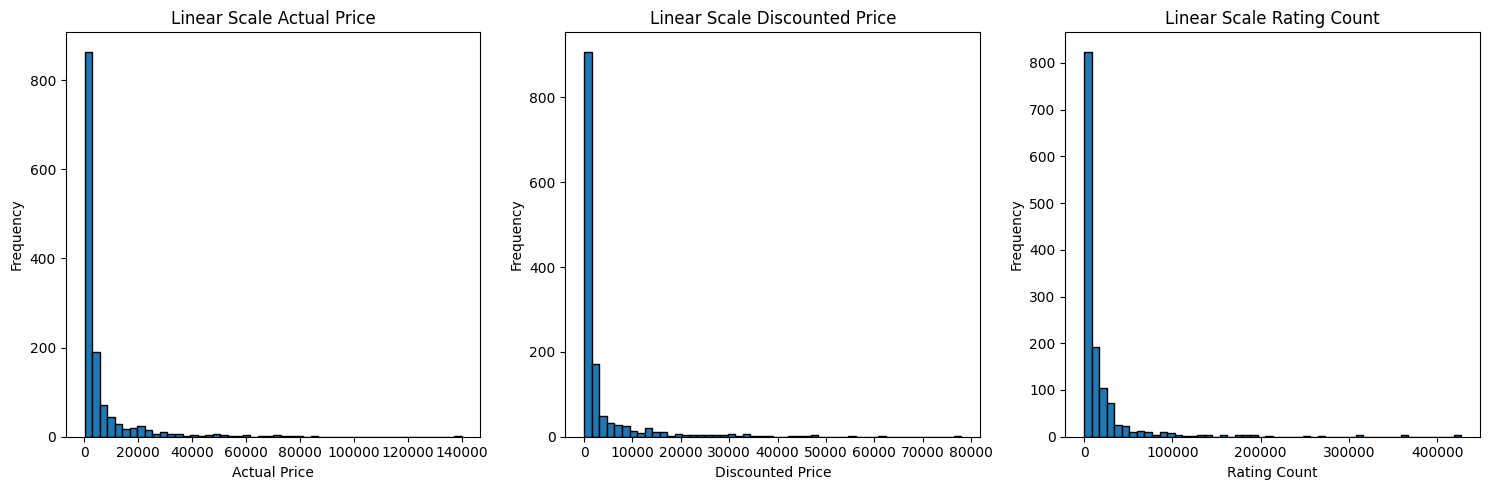

In [23]:
# Your code here
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(deduped_copy['actual_price'], bins=50,edgecolor='black')
plt.xlabel('Actual Price')
plt.ylabel('Frequency')
plt.title('Linear Scale Actual Price')

plt.subplot(1, 3, 2)
plt.hist(deduped_copy['discounted_price'], bins=50,edgecolor='black')
plt.xlabel('Discounted Price')
plt.ylabel('Frequency')
plt.title('Linear Scale Discounted Price')

plt.subplot(1, 3, 3)
plt.hist(deduped_copy['rating_count'], bins=50,edgecolor='black')
plt.xlabel('Rating Count')
plt.ylabel('Frequency')
plt.title('Linear Scale Rating Count')

plt.tight_layout()
plt.show()

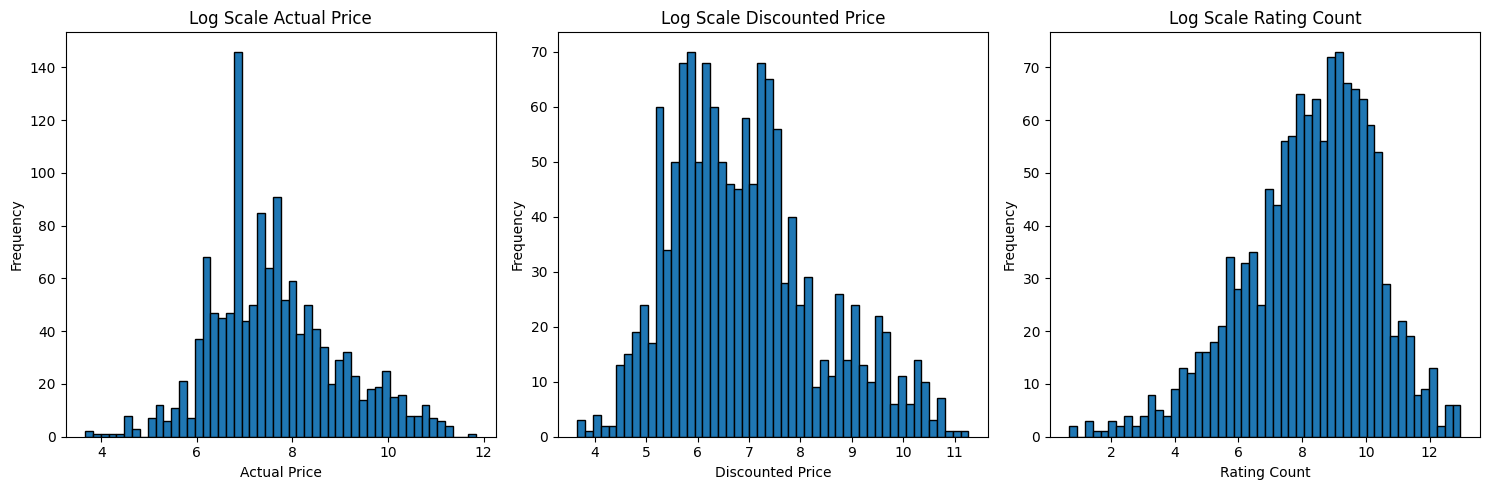

In [24]:
# Your code here
from numpy import log
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(log(deduped_copy['actual_price']), bins=50,edgecolor='black')
plt.xlabel('Actual Price')
plt.ylabel('Frequency')
plt.title('Log Scale Actual Price')

plt.subplot(1, 3, 2)
plt.hist(log(deduped_copy['discounted_price']), bins=50,edgecolor='black')
plt.xlabel('Discounted Price')
plt.ylabel('Frequency')
plt.title('Log Scale Discounted Price')

plt.subplot(1, 3, 3)
plt.hist(log(deduped_copy['rating_count']), bins=50,edgecolor='black')
plt.xlabel('Rating Count')
plt.ylabel('Frequency')
plt.title('Log Scale Rating Count')

plt.tight_layout()
plt.show()

**Your answer:**

For `actual_price`, `discounted_price`, and `rating_count`, the **log-scale histogram is more informative** than the linear one.

**Why the linear histogram falls short**:
These variables are strongly right-skewed (confirmed by mean >> median above). On a linear scale, the few extreme high values (e.g. `actual_price` up to ₹139,900, `rating_count` up to 426,973) force most of the data into a single narrow bar near zero. The bulk of the distribution — where most products actually sit — becomes invisible, and the shape looks like a single spike rather than a distribution.

**Why the log-scale histogram is better**:
Taking `log(x)` compresses the large values and stretches out the small ones, spreading the data more evenly across the range. This reveals:
- The underlying shape of the distribution (closer to normal/bell-shaped), rather than one dominant bin
- Multiple clusters or modes that were hidden in the linear view (e.g. common price tiers)
- A clearer sense of where "typical" values lie, consistent with the median being more representative than the mean

The log transformation doesn't change the underlying data, only how it's visualized — but for right-skewed variables like these, it turns an uninformative single-spike plot into one that actually shows the distribution's shape, spread, and central tendency.

**B1.3** Plot the distribution of `rating`. What fraction of products are rated 4.0 or above? What does this imply for a rating-prediction model?

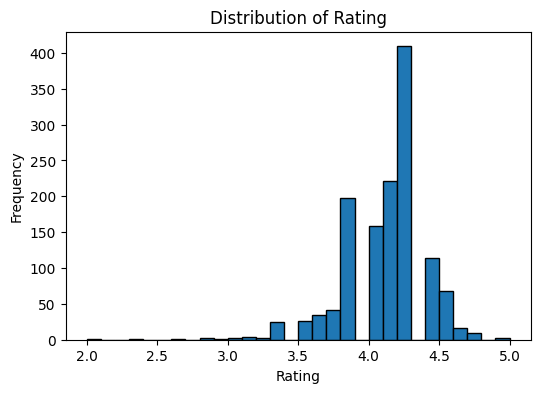

Fraction of products rated 4 and above: 74.64%


In [25]:
# Your code here
plt.figure(figsize=(6, 4))
plt.hist(deduped_copy['rating'],bins=30,edgecolor='black')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.title('Distribution of Rating')
plt.show()

frac_4_and_above = (deduped['rating'] >= 4).mean()
print(f"Fraction of products rated 4 and above: {frac_4_and_above:.2%}")

**Your answer:**

The distribution of `rating` is **left-skewed**, concentrated between 4.0–4.5, with a long thin tail toward lower ratings. **74.64%** of products are rated 4 or above.

#### Implication for rating prediction
Because the vast majority of products cluster tightly near the high end (mean ≈ 4.09, std ≈ 0.30), a model trained on this data has little variation to learn from. It will tend to learn that predicting a value close to 4–4.2 for *every* product minimizes overall error, since that's where most of the data sits.

This creates two problems:
- **For the majority class (already highly rated products):** predictions will look accurate, since most true values are already close to that central range.
- **For the minority of lower-rated products:** the model will **overestimate** their rating, since it has few low-rating examples to learn the pattern from, and is biased toward predicting near the mean.

So the *overall* training error may look deceptively low (since most points are near the mean already), but the model will systematically fail on the underrepresented low-rating products — this is where test error will concentrate, particularly as **overestimation bias** on genuinely poor products.

**B1.4** Plot the distribution of `discount_percentage`.

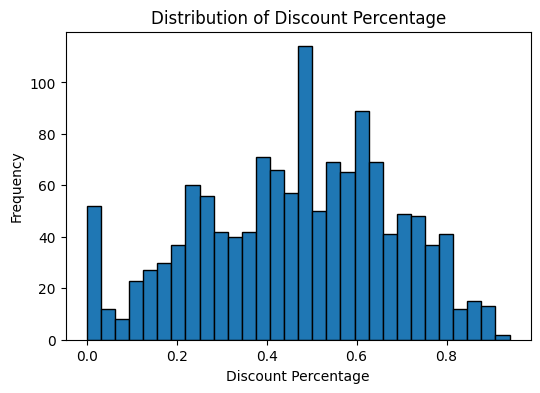

In [26]:
# Your code here
plt.figure(figsize=(6, 4))
plt.hist(deduped_copy['discount_percentage'],bins=30,edgecolor='black')
plt.xlabel('Discount Percentage')
plt.ylabel('Frequency')
plt.title('Distribution of Discount Percentage')
plt.show()


**Your answer:**

The distribution of `discount_percentage` is **fairly normal/bell-shaped**, concentrated between 0.46–0.48.

## B2. Category analysis (6 marks)

**B2.1** Split `category` on `|` and extract the top-level (`main_category`) and last-level (`sub_category`) labels.

In [27]:
# Your code here
print(deduped_copy['category'].nunique()) 

211


In [28]:
deduped_copy['category'] = deduped_copy['category'].str.split('|')
#(deduped_copy['category'].str.len() == 1).sum()
deduped_copy['main_category'] = deduped_copy['category'].str[0] #take first item in list as main-category
deduped_copy['sub_category'] = deduped_copy['category'].str[-1] #take last item in list as sub-category
deduped_copy[['category', 'main_category', 'sub_category']].head(5)

,category,main_category,sub_category
0,"[Electronics, HomeTheater,TV&Video, Accessorie...",Electronics,HDMICables
1,"[Electronics, HomeTheater,TV&Video, Accessorie...",Electronics,HDMICables
2,"[Electronics, HomeTheater,TV&Video, Accessorie...",Electronics,HDMICables
3,"[Electronics, Headphones,Earbuds&Accessories, ...",Electronics,In-Ear
4,"[Electronics, Headphones,Earbuds&Accessories, ...",Electronics,In-Ear


In [29]:
deduped_copy[['main_category', 'sub_category']].nunique()

main_category      9
sub_category     207
dtype: int64

**B2.2** Bar chart of product counts per `main_category`, and the top 15 sub-categories by count.

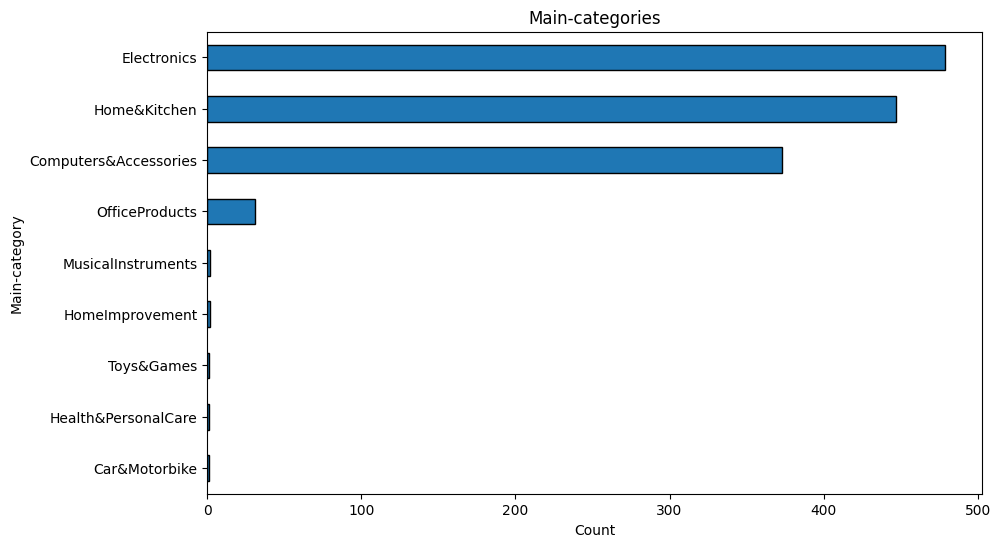

In [30]:
# Your code here
main_categories = deduped_copy['main_category'].value_counts()

plt.figure(figsize=(10,6))
main_categories.plot(kind='barh',edgecolor='black')
plt.xlabel('Count')
plt.ylabel('Main-category')
plt.title('Main-categories')
plt.gca().invert_yaxis()  
plt.show()

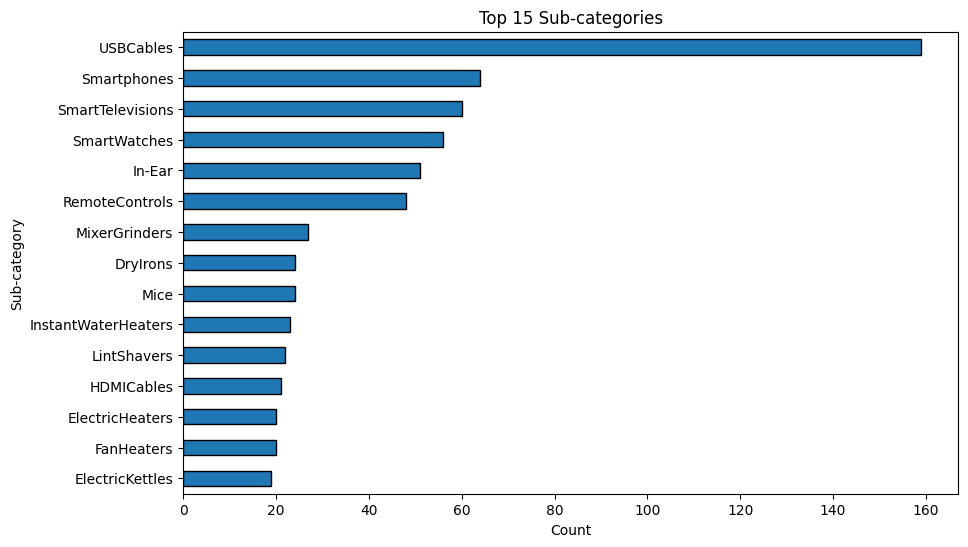

In [31]:
top15 = deduped_copy['sub_category'].value_counts().head(15)

plt.figure(figsize=(10,6))
top15.plot(kind='barh',edgecolor='black')
plt.xlabel('Count')
plt.ylabel('Sub-category')
plt.title('Top 15 Sub-categories')
plt.gca().invert_yaxis()  
plt.show()

**Your answer:**

**Main-category:** The dataset is heavily dominated by three categories — **Electronics** (~480), **Home&Kitchen** (~450), and **Computers&Accessories** (~375) — which together account for the vast majority of products. All remaining categories (OfficeProducts, MusicalInstruments, HomeImprovement, etc.) have negligible counts (<30 each), indicating a **highly imbalanced category distribution**.

**Sub-category:** **USBCables** alone accounts for ~160 products, far ahead of the next closest (Smartphones, SmartTelevisions, SmartWatches, all ~55–65). This mirrors the main-category imbalance at a finer grain — a small number of sub-categories dominate, while the rest of the top 15 trail off gradually.

Any category-based analysis or model (e.g. predicting price/rating by category) will be skewed toward Electronics-related products, particularly USB cables. Rare categories have too few samples for reliable comparison or generalization.

**B2.3** Compare median price, median discount and mean rating across main categories. Which category is discounted most heavily?

In [32]:
# Your code here
deduped_copy_summary = deduped_copy.groupby(['main_category']).agg(
    total_products=('product_id', 'nunique'),
    median_actual_price=('actual_price', 'median'),
    median_discounted_price=('discounted_price', 'median'),
    avg_discount_percentage=('discount_percentage', 'mean'),
    avg_rating=('rating', 'mean'))  

deduped_copy_summary.sort_values('total_products', ascending=False)

,total_products,median_actual_price,median_discounted_price,avg_discount_percentage,avg_rating
main_category,,,,,
Electronics,479,2999.0,1299.0,0.496159,4.075574
Home&Kitchen,447,2000.0,1199.0,0.401745,4.040716
Computers&Accessories,373,999.0,399.0,0.530938,4.154692
OfficeProducts,31,210.0,178.0,0.123548,4.309677
HomeImprovement,2,799.0,337.0,0.575000,4.250000
MusicalInstruments,2,1347.0,638.0,0.460000,3.900000
Car&Motorbike,1,4000.0,2339.0,0.420000,3.800000
Health&PersonalCare,1,1900.0,899.0,0.530000,4.000000
Toys&Games,1,150.0,150.0,0.000000,4.300000


**Your answer:**

**Median prices:** `Car&Motorbike` has the highest median actual price (₹4000) despite only 1 product, so it's not representative — just a single expensive item. Among the well-populated categories, **Electronics** (₹2999) and **Home&Kitchen** (₹2000) have notably higher median prices than **Computers&Accessories** (₹999) and **OfficeProducts** (₹210), suggesting Electronics and Home&Kitchen skew toward pricier products even after accounting for the outlier-prone mean.

**Median discounted price** follows the same order as actual price across categories (Electronics > Home&Kitchen > Computers&Accessories > OfficeProducts), indicating discounting doesn't change relative price ranking between categories — a product's category still roughly determines its price tier even post-discount.

**Average rating:** Ratings are fairly consistent across the major categories — `OfficeProducts` (4.31), `Computers&Accessories` (4.15), `Electronics` (4.08), and `Home&Kitchen` (4.04) all sit in a narrow 4.0–4.3 band, so rating doesn't vary much with how heavily a category is discounted. Notably, `OfficeProducts` has the **lowest discount** (12.3%) but the **highest average rating** (4.31), suggesting products don't need heavy discounting to be well-rated. The small categories show more spread (3.8–4.3), but again aren't reliable given their tiny sample sizes.

Heavier discounting doesn't correlate with better or worse ratings among the well-sampled categories — `Computers&Accessories` is discounted most but rated similarly to the less-discounted `Electronics` and `Home&Kitchen`, while the least-discounted `OfficeProducts` actually has the highest rating.

## B3. Bivariate and multivariate analysis (8 marks)

**B3.1** Scatter plot of `discount_percentage` vs `rating`. Do bigger discounts go with better or worse ratings?

Text(0.5, 1.0, 'Discount Percentage vs Rating')

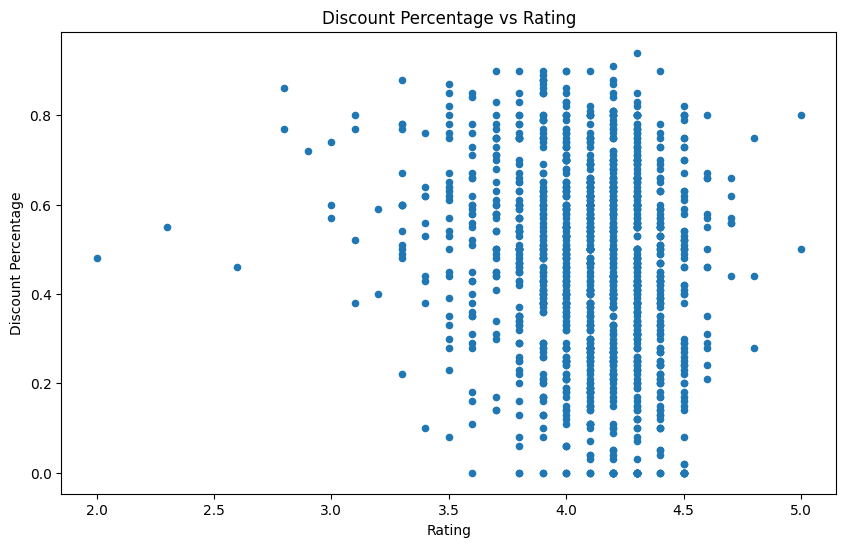

In [33]:
# Your code here
from matplotlib.pyplot import figure, plot, ylabel, xlabel, title

figure(figsize=(10,6))
deduped_copy.plot(kind='scatter',x='rating',y='discount_percentage',ax=plt.gca())
xlabel('Rating')
ylabel('Discount Percentage')
title('Discount Percentage vs Rating')



**Your answer:**

The scatter plot shows **no clear relationship** between `discount_percentage` and `rating`. For almost every rating value, discount percentages are spread across the full range (0% to ~90%) — there's no visible upward or downward trend.

**Ratings (x-axis)** are tightly clustered between 3.5–4.5, consistent with the earlier distribution analysis (left-skewed, most products rated highly). **Discount percentage (y-axis)**, by contrast, is well spread out across its entire range at almost every rating level, showing no such concentration.

A product's discount level tells you almost nothing about how it will be rated, and vice versa — heavily discounted products are rated just as well (or poorly) as lightly discounted ones. This suggests `discount_percentage` alone would be a weak predictor of `rating`, and any pricing strategy that assumes "bigger discounts drive better ratings" isn't supported by this data.

**B3.2** Scatter plot of `log(rating_count)` vs `rating`. Are popular products rated higher?

Text(0.5, 1.0, 'Log(Rating Count) vs Rating')

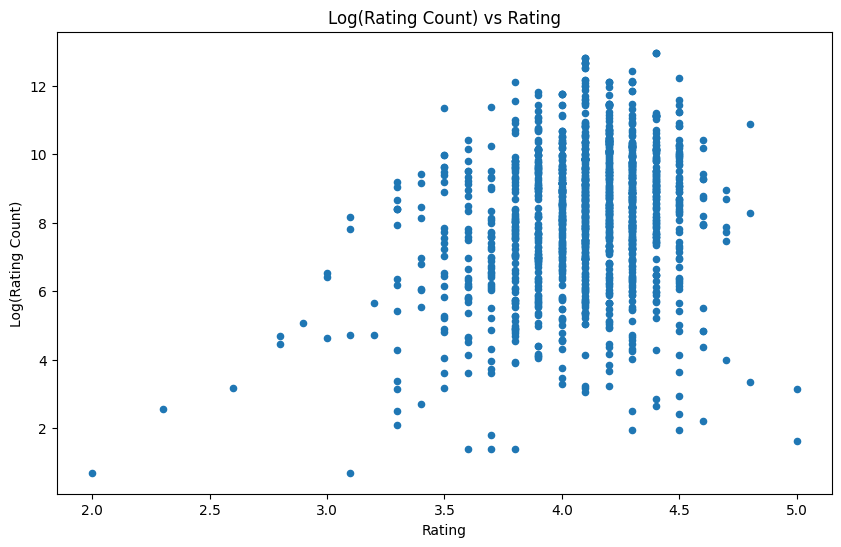

In [34]:
# Your code here
figure(figsize=(10,6))
deduped_copy2 = deduped_copy.copy()
deduped_copy2['log_rating_count'] = np.log(deduped_copy2['rating_count'])
deduped_copy2.plot(kind='scatter', x='rating', y='log_rating_count', ax=plt.gca())
xlabel('Rating')
ylabel('Log(Rating Count)')
title('Log(Rating Count) vs Rating')

**Your answer:**

The scatter plot shows **no strong relationship between popularity (rating count) and rating**. For every rating level from ~3.3 to 4.5, `log(rating_count)` spans nearly the full observed range (from ~2 to ~13), meaning both highly popular and rarely-rated products can end up with similar ratings.

**Popular products are not rated higher.** If popularity drove better ratings, we'd expect points to trend upward — high rating_count clustering at high rating values. Instead, the spread is roughly vertical at every rating level, especially in the dense 3.7–4.5 range, showing products with very few ratings and products with tens of thousands of ratings landing at the same rating value.

**One asymmetry worth noting:** products with **very low** rating counts (bottom of the plot, log ≈ 0–3) are almost entirely restricted to ratings between 2.0–3.8 — there are no low-popularity products at the high end (4.5+) with very low counts alone. This suggests a floor effect rather than a positive trend: a product needs *some* minimum engagement to reach the highest ratings, but beyond that baseline, more popularity doesn't push ratings higher.

**Implication:** `rating_count` is a weak predictor of `rating` on its own. High review volume does not indicate a better-loved product, it may simply reflect a product's overall sales volume or market reach, independent of quality perception.

**B3.3** Box plots of `rating` by `main_category`.

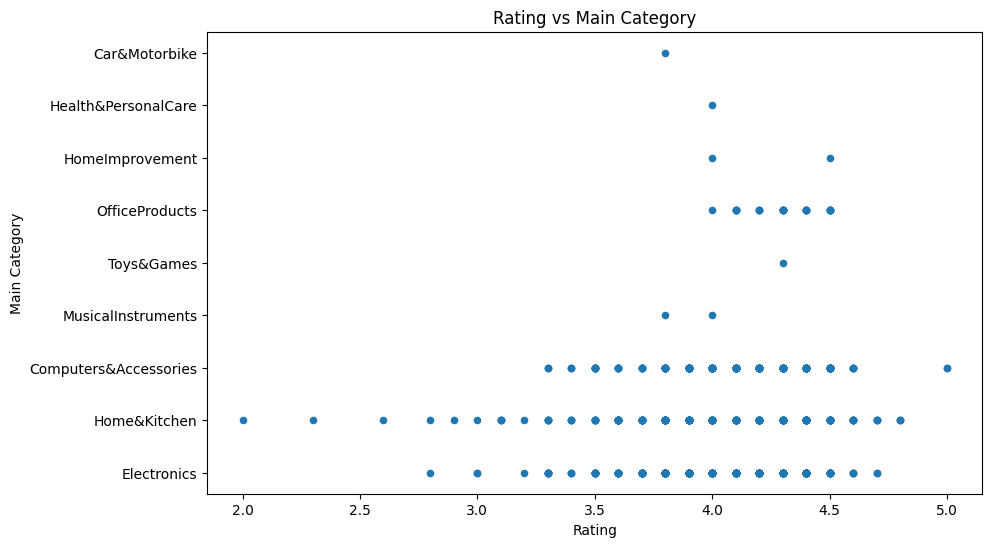

In [35]:
# Your code here
figure(figsize=(10,6))
deduped_copy2.plot(kind='scatter', y='main_category', x='rating', ax=plt.gca())
ylabel('Main Category')
xlabel('Rating')
title('Rating vs Main Category') 
plt.show()

**Your answer:**

**Electronics and Home&Kitchen** (the two largest categories) show the **widest spread of ratings**, ranging from as low as 2.0–3.2 up to 4.5+. This is expected given their large product counts — more products means more opportunity for both very good and very poor ratings to appear.

**Smaller categories cluster tightly near high ratings.** `OfficeProducts`, `HomeImprovement`, `Health&PersonalCare`, `Toys&Games`, and `Car&Motorbike` all have their points concentrated between roughly 4.0–5.0, with no low outliers. This isn't necessarily because these categories are inherently better rated — it's more likely a **sample size effect**: with only 1–31 products each, there simply aren't enough data points for a poorly-rated outlier to appear.

**Computers&Accessories** sits in between — mostly clustered around 4.0–4.7, similar to the small categories, but with one low outlier near 5.0 rating shown (leftmost point, lowest numeric rating side isn't visible clearly here — worth double-checking that point specifically).

Apparent differences in rating "quality" across categories are confounded by sample size. The large categories (`Electronics`, `Home&Kitchen`) aren't necessarily worse — they just have enough products to reveal their full rating range, while small categories haven't had the chance to show a bad rating yet. Any category-level rating comparison should account for this before concluding some categories perform better than others.

**B3.4** Correlation heatmaps (Pearson and Spearman) of the numeric columns. Explain any differences between the two.

In [36]:
# Your code here
deduped_copy2.select_dtypes(include=[np.number]).dtypes


discounted_price       float64
actual_price           float64
discount_percentage    float64
rating                 float64
rating_count             int64
log_rating_count       float64
dtype: object

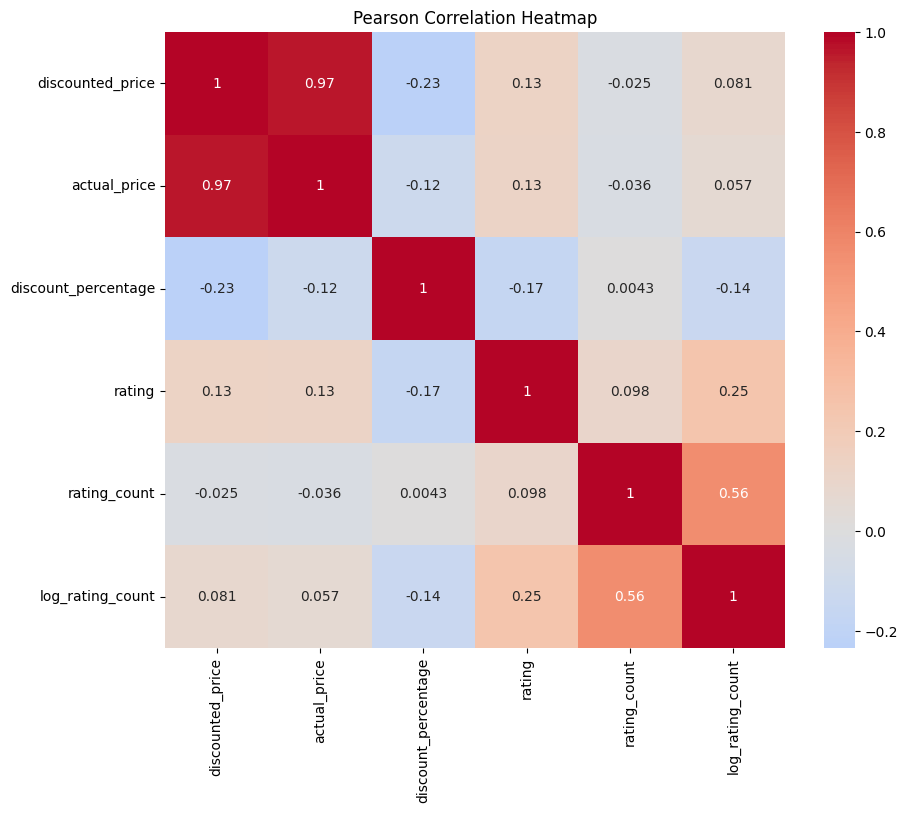

In [37]:
numeric_columns = deduped_copy2.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 8))
sns.heatmap(deduped_copy2[numeric_columns].corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Pearson Correlation Heatmap')
plt.show()


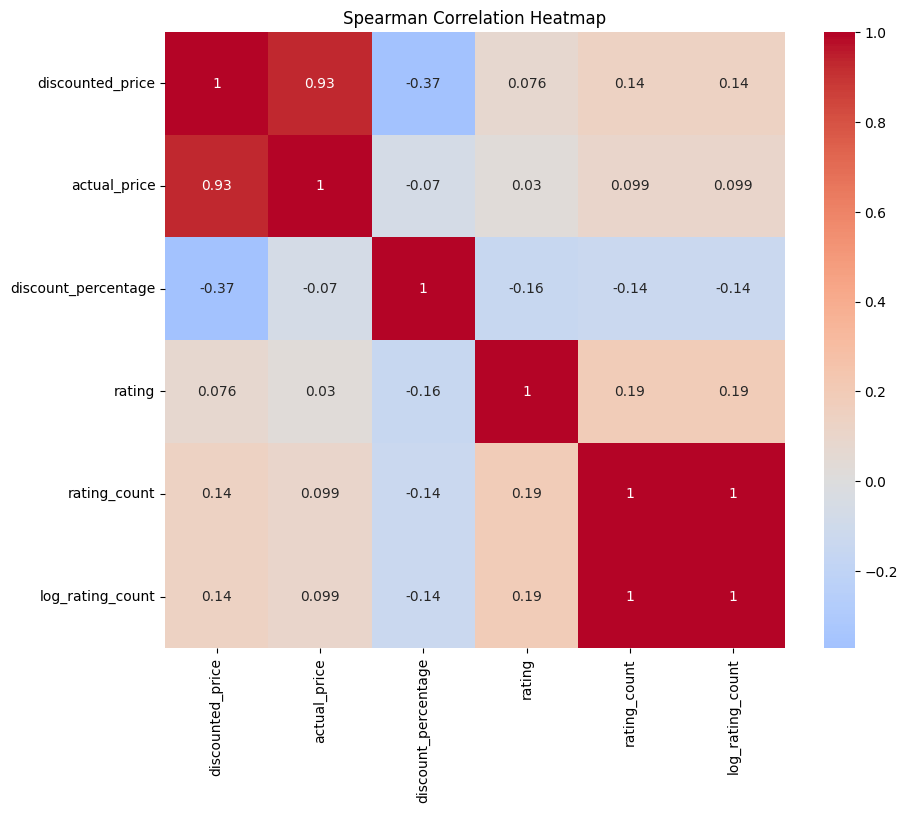

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(deduped_copy2[numeric_columns].corr(method='spearman'), annot=True, cmap='coolwarm', center=0)
plt.title('Spearman Correlation Heatmap')
plt.show()

**Your answer:**

The differences between the two heatmaps highlight the presence of **non-linear relationships and the influence of outliers** in the data. Pearson correlation measures the strength of **linear relationships** and is more sensitive to extreme values, while Spearman correlation is rank-based and captures **monotonic relationships**, making it more robust to outliers and less dependent on the data being normally distributed.

A key example is the relationship between `rating_count` and `log_rating_count`: Pearson gives a correlation of **0.56**, whereas Spearman gives **1.00**. This occurs because the logarithmic transformation changes the numerical spacing between observations, so the relationship is no longer linear on the original scale. However, the transformation preserves the **ranking of observations**, allowing Spearman to capture the relationship perfectly.

Similarly, the correlation between `discounted_price` and `discount_percentage` is stronger using Spearman (**−0.37**) than Pearson (**−0.23**), suggesting that the relationship is more **monotonic than strictly linear**.

Overall, the differences between the two correlation maps suggest that some relationships in the dataset are **non-linear but monotonic**, which Spearman can capture better than Pearson. 

## B4. Text and reviewer peek (4 marks)

**B4.1** Count the reviews per row (split `review_id` on commas) and plot the distribution.

In [39]:
# Your code here
deduped_copy2['review_id'].head(5)

0    R1FKOKZ3HHKJBZ,R2WNMZI1EXTA0H,RCA1M3W4RIXUR,R3...
1    R1FKOKZ3HHKJBZ,R2WNMZI1EXTA0H,RCA1M3W4RIXUR,R3...
2    R1FKOKZ3HHKJBZ,R2WNMZI1EXTA0H,RCA1M3W4RIXUR,R3...
3    R2DD2M5YARW7R2,R2M9ZYNGGV1ZLN,RNWNTRNLSJWSB,R3...
4    R2DD2M5YARW7R2,R2M9ZYNGGV1ZLN,RNWNTRNLSJWSB,R3...
Name: review_id, dtype: object

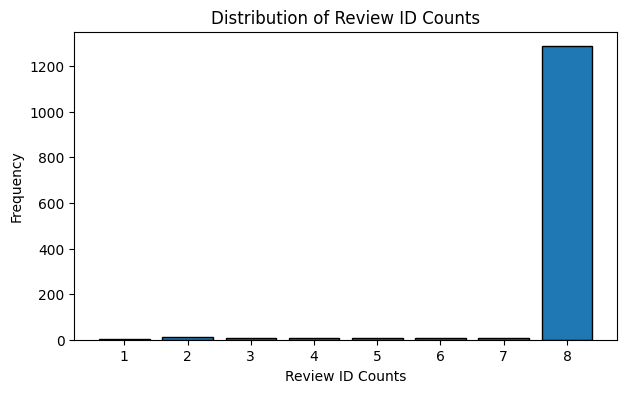


Distribution of Review IDs per Row:
review_id
1       2
2      10
3       7
4       8
5       8
6       6
7       9
8    1287
Name: count, dtype: int64


In [40]:
if 'deduped_copy2' in locals() and 'review_id' in deduped_copy2.columns:
        review_id_count = (
        deduped_copy2['review_id']
        .fillna('')
        .astype(str)
        .apply(lambda x: len([r for r in x.split(',') if r.strip()]))
    )

id_distribution = review_id_count.value_counts().sort_index()

plt.figure(figsize=(7,4))
plt.bar(id_distribution.index, id_distribution.values, edgecolor='black')
plt.xlabel('Review ID Counts')
plt.ylabel('Frequency')
plt.title('Distribution of Review ID Counts')
plt.show()

print("\nDistribution of Review IDs per Row:")
print(id_distribution)

**Your answer:**

The distribution shows a **strong concentration of rows containing 8 review IDs**. Out of the **1,337 total rows**, **1,287 rows (approximately 96.3%)** contain exactly 8 review IDs. The remaining 50 rows contain between 1 and 7 review IDs, with only a small number of observations in each category.

This indicates that the dataset is **highly concentrated at 8 review IDs per row**, making 8 the dominant pattern in the data. The smaller number of rows with fewer than 8 IDs may represent cases where fewer reviews were available or where the data was structured differently.

Approximately **96.3% of the rows contain 8 review IDs**, while only **3.7% contain fewer than 8 IDs**.

**B4.2** Find the most frequent words in `review_title` for products rated ≥ 4.3 vs < 3.8 (after removing stop words). What differs?

In [41]:
# Your code here
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

#remove stop words and punctuation, convert to lowercase, and split into words
import string
def preprocess_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = [word for word in text.split() if word not in stop_words]
    return words

#section top rated products with review >=4.3 and low rated. with<3.8 ratings 
top_rated = deduped_copy2[deduped_copy2['rating'] >= 4.3]
low_rated = deduped_copy2[deduped_copy2['rating'] < 3.8]

#print(len(top_rated), len(low_rated))

In [42]:
#identify most frequent words in review_title for top rated and low rated products
from collections import Counter
top_rated_words = Counter()
for title in top_rated['review_title'].astype(str):
    top_rated_words.update(preprocess_text(title))

low_rated_words = Counter()
for title in low_rated['review_title'].astype(str):
    low_rated_words.update(preprocess_text(title))


In [43]:
print("\nTop rated - most common words:")
for word, count in top_rated_words.most_common(10):
    print(f"{word}: {count}")

print("\nLow rated - most common words:")   
for word,count in low_rated_words.most_common(10):
    print(f"{word}: {count}")


Top rated - most common words:
good: 344
product: 260
quality: 109
productgood: 67
money: 56
nice: 55
price: 50
buy: 49
easy: 48
value: 46

Low rated - most common words:
good: 108
product: 90
quality: 46
working: 25
one: 22
buy: 21
price: 20
money: 17
productgood: 15
well: 15


In [44]:
#words relatively more common in low-rated titles than top-rated
low_rated_distinctive = Counter()
for word, count in low_rated_words.items():
    top_count = top_rated_words.get(word, 0)
    low_rated_distinctive[word] = count - (top_count * (len(low_rated) / len(top_rated)))

low_rated_distinctive.most_common(15)

[('working', 13.16546762589928),
 ('bad', 10.956834532374101),
 ('one', 10.503597122302159),
 ('watch', 9.294964028776977),
 ('well', 9.25179856115108),
 ('quality', 9.143884892086334),
 ('productnot', 8.633093525179856),
 ('works', 8.25179856115108),
 ('ok', 7.266187050359712),
 ('button', 6.323741007194244),
 ('used', 6.294964028776978),
 ('remote', 5.971223021582734),
 ('time', 5.280575539568345),
 ('voice', 5.0),
 ('original', 4.956834532374101)]

In [45]:
top_rated_distinctive = Counter()
for word, count in top_rated_words.items():
    low_count = low_rated_words.get(word, 0)
    top_rated_distinctive[word] = count - (low_count * (len(top_rated) / len(low_rated)))

top_rated_distinctive.most_common(15)

[('cable', 37.04255319148936),
 ('tv', 30.085106382978722),
 ('mouse', 30.0),
 ('fast', 28.085106382978722),
 ('good', 24.595744680851055),
 ('easy', 24.340425531914892),
 ('productgood', 22.638297872340424),
 ('nice', 22.46808510638298),
 ('budget', 22.04255319148936),
 ('best', 19.340425531914892),
 ('charging', 19.085106382978722),
 ('decent', 19.0),
 ('c', 17.0),
 ('moneygood', 16.085106382978722),
 ('better', 16.0)]

**Your answer:**

These word counts come from 417 top-rated products (rating ≥ 4.3, ~31% of the 1337-row dataset) and 141 low-rated products (rating < 3.8, ~11%). Together they cover only ~42% of all products — the remaining ~47% fall in the middle band (3.8–4.3) and aren't represented in either list. The low-rated group is notably smaller, so its word counts are more susceptible to noise from individual products.

**What's similar:** Both groups share the same top 3 words — `good`, `product`, `quality` — in the same order. This isn't surprising: these are generic, high-frequency terms in almost any product review, regardless of sentiment, and don't distinguish satisfaction level on their own.

**What differs:**
- **Top-rated titles** mention `nice`, `easy`, `value`, `buy`, and `price` prominently — suggesting reviewers emphasize ease of use and perceived value for money when happy with a product.
- **Low-rated titles** notably include `working` (25 mentions) and `one` (22) — words that don't appear in the top-rated top 10 at all. `working` in particular strongly suggests functional complaints ("not working," "stopped working"), a theme absent from the top-rated language.
- `productgood` appears in both lists but is far more frequent in top-rated (67) than low-rated (15) — likely an artifact of concatenated review titles (e.g. "Good product" with punctuation stripped, merging into one token), worth cleaning up if this word is prioritized further.

Raw top-10 word counts are dominated by generic sentiment words shared across both groups, so they don't cleanly separate the two categories. The `top_rated_distinctive` / `low_rated_distinctive` scores are the more useful signal here, since they control for these shared high-frequency words and highlight what's genuinely different — like `working` skewing toward low-rated titles.

## B5. Key insights
List **five key insights** from Part B, each backed by a number from your analysis.

1.  Ratings are heavily skewed toward high values, limiting variation to explain:
The `rating` distribution is left-skewed, clustered tightly around a mean of **4.09** (median 4.10, std ≈ 0.30). A large majority of products are rated between 3.8–4.5. This means any model or comparison of "what drives rating" has very little variance to work with — most products already sit near the ceiling, so downstream predictions risk **overestimating** poorly-rated products, which are a minority.
2. Rating count (popularity) shows no meaningful relationship with rating:
Plotting `log(rating_count)` against `rating` shows values spread across the full range (log ≈ 2–13) at nearly every rating level from 3.3–4.5, with no upward trend. The one pattern present is a **floor effect**: products with very low rating counts are confined to lower ratings (2.0–3.8), suggesting a product needs some minimum engagement to reach the top ratings, but beyond that baseline, more popularity does not correspond to higher ratings.
3. Discount percentage shows no meaningful relationship with rating either:
Across the full discount range (0%–~90%), discount percentage is spread widely at almost every rating value (3.5–4.5). There is no visible trend suggesting heavier discounts correlate with better or worse ratings — a product discounted 80% is rated just as unpredictably as one discounted 10%.
4. Category-level rating differences are confounded by sample size, not necessarily category effect:
Average ratings across the three major categories are close: `OfficeProducts` (4.31, n=31), `Computers&Accessories` (4.15, n=373), `Electronics` (4.08, n=479), `Home&Kitchen` (4.04, n=447). Notably, `OfficeProducts` has both the **lowest average discount (12.3%)** and the **highest average rating**, weakly reinforcing insight #3 — heavy discounting isn't necessary for good ratings. Smaller categories (1–2 products) show more rating spread (3.8–4.3), but this reflects limited sample size rather than a real category effect, and shouldn't be over-interpreted.
5. Review language distinguishes sentiment more than any numeric variable does:
Word-frequency analysis of `review_title` shows top-rated (≥4.3, n=417) and low-rated (<3.8, n=141) products share generic top words (`good`, `product`, `quality`), but diverge on specific terms: low-rated titles disproportionately feature **`working`** (25 mentions, absent from top-rated's top 10) — a strong marker for functional complaints — while top-rated titles emphasize **`value`**, **`easy`**, and **`nice`**. This suggests **text-based sentiment features are likely to be far more predictive of rating than any of the numeric variables tested** (rating_count, discount_percentage, category).

##### Overall takeaway
None of the numeric variables examined (`rating_count`, `discount_percentage`, `main_category`) show a strong standalone relationship with `rating`. The most promising signal for predicting or explaining rating differences comes from **review text content**, not pricing or popularity metrics.

# Part C — Feature engineering (25 marks)
Build a feature matrix `X` for predicting `rating`. Create **at least 10 new features**, with at least one from each group (price, popularity, category, text).

**C1. Price features.** Suggested: `discount_amount`, `log_actual_price`, `log_discounted_price`, `price_bucket` (quantile bins).

In [46]:
# Your code here
deduped_copy3 = deduped_copy2.copy()
deduped_copy3['discount_amount'] = deduped_copy2['actual_price'] - deduped_copy2['discounted_price']
deduped_copy3['log_actual_price'] = np.log(deduped_copy3['actual_price'])
deduped_copy3['log_discounted_price'] = np.log(deduped_copy3['discounted_price'])
deduped_copy3['log_discount_amount'] = deduped_copy3['log_actual_price'] - deduped_copy3['log_discounted_price']

#deduped_copy3.describe()
#median_discount_amount = deduped_copy3['discount_amount'].median()
#median_discount_amount

**C2. Popularity features.** Suggested: `log_rating_count`, `is_popular` (above 75th percentile), `rating_count_rank_in_category`.

In [47]:
# Your code here
deduped_copy3.columns

Index(['product_id', 'product_name', 'category', 'discounted_price',
       'actual_price', 'discount_percentage', 'rating', 'rating_count',
       'about_product', 'user_id', 'review_id', 'review_title',
       'main_category', 'sub_category', 'log_rating_count', 'discount_amount',
       'log_actual_price', 'log_discounted_price', 'log_discount_amount'],
      dtype='object')

In [48]:
#label is_popular=1 for those above the 75th percentile of log review_count and is_popular=0 for those below the 75th percentile of log review_count
deduped_copy3['is_popular'] = (deduped_copy3['log_rating_count'] > deduped_copy3['log_rating_count'].quantile(0.75)).astype(int)
#deduped_copy3[['product_id', 'product_name', 'log_rating_count', 'is_popular']].head(10)
#deduped_copy3['is_popular'].value_counts()
deduped_copy3[['is_popular','log_rating_count']].head(10)

,is_popular,log_rating_count
0,1,12.964476
1,1,12.964476
2,1,12.964476
3,1,12.804120
4,1,12.804120
5,1,12.804115
6,1,12.656626
7,1,12.656626
8,1,12.656613
9,1,12.656613


**C3. Category features.** Suggested: `main_category`, `sub_category`, `category_depth`; group sub-categories with fewer than 10 products into `Other`.

In [49]:
# Your code here
subcat_counts = deduped_copy3.groupby('sub_category')['product_name'].nunique()
subcat_counts_lt_10 = subcat_counts[subcat_counts < 10].index

deduped_copy3['Other'] = (deduped_copy3['sub_category'].isin(subcat_counts_lt_10))

deduped_copy3['category_depth'] = deduped_copy3['category'].str.len()

deduped_copy3[['main_category','sub_category', 'Other', 'category_depth']].head(10)




,main_category,sub_category,Other,category_depth
0,Electronics,HDMICables,False,5
1,Electronics,HDMICables,False,5
2,Electronics,HDMICables,False,5
3,Electronics,In-Ear,False,4
4,Electronics,In-Ear,False,4
5,Electronics,In-Ear,False,4
6,Electronics,Smartphones,False,4
7,Electronics,Smartphones,False,4
8,Electronics,Smartphones,False,4
9,Electronics,Smartphones,False,4


In [50]:
deduped_copy3['Other'].value_counts()

Other
False    913
True     424
Name: count, dtype: int64

**C4. Text features.** Suggested: `name_length`, `about_length`, `n_reviews`, `review_sentiment`, keyword flags from `product_name` (e.g. `is_cable`, `is_wireless`).

In [51]:
# Your code here
deduped_copy3['about_length']=deduped_copy3['about_product'].str.len()

In [52]:
#%pip install textblob
from textblob import TextBlob
import sys
from textblob import TextBlob

def avg_review_sentiment(text):
    if pd.isna(text):
        return 0.0
    titles = [t.strip() for t in str(text).split(',') if t.strip()]
    if not titles:
        return 0.0
    scores = [TextBlob(t).sentiment.polarity for t in titles]
    return float(np.mean(scores))

deduped_copy3['review_sentiment'] = deduped_copy3['review_title'].apply(avg_review_sentiment)
deduped_copy3['review_sentiment'].describe()

count    1337.000000
mean        0.388697
std         0.151458
min        -0.500000
25%         0.293750
50%         0.393148
75%         0.490608
max         0.767708
Name: review_sentiment, dtype: float64

In [53]:
deduped_copy3[['review_sentiment','review_title']].head(10)

,review_sentiment,review_title
0,0.262500,"It's quite good and value for money,Works well..."
1,0.262500,"It's quite good and value for money,Works well..."
2,0.262500,"It's quite good and value for money,Works well..."
3,0.461111,"Best value for money,HEAD PHONE POUCH NOT RECE..."
4,0.461111,"Best value for money,HEAD PHONE POUCH NOT RECE..."
5,0.461111,"Best value for money,HEAD PHONE POUCH NOT RECE..."
6,0.530556,"Best phone for below normal use,Good mobile fo..."
7,0.530556,"Best phone for below normal use,Good mobile fo..."
8,0.530556,"Best phone for below normal use,Good mobile fo..."
9,0.530556,"Best phone for below normal use,Good mobile fo..."


**C5. Feature table.** Fill in one row per new feature.

| Feature | Formula / how computed | Why it might help |
| --- | --- | --- |
| `review_sentiment` | Average TextBlob polarity score (-1 to +1) across each product's comma-split review titles | Captures the actual sentiment expressed in reviews rather than relying on numeric proxies. Earlier word-frequency analysis showed review language (e.g. "working" vs "value", "nice") differs meaningfully between high- and low-rated products, while `rating_count` and `discount_percentage` showed no relationship with rating — so this is expected to be the **strongest predictor** among the new features. |
| `about_length` | `len(about_product)` — character (or word) count of the product description | Longer, more detailed descriptions may signal more established/higher-quality listings, or conversely indicate overcomplicated products; useful as a proxy for listing effort or product complexity. |
| `sub_category` (grouped, "Other") | Original `sub_category` value, replaced with `"Other"` if that sub-category has fewer than 10 products | Prevents the model from trying to learn from sub-categories with too few samples to generalize, reducing overfitting to rare, noisy categories while retaining signal from well-represented ones. |
| `main_category` | First segment of the pipe-split `category` string | Broad product grouping; lets the model account for systematic rating differences across major categories (e.g. `OfficeProducts` averaged higher ratings than `Electronics`). |
| `category_depth` | Count of segments in the split `category` list (`len(category)`) | Captures how deeply nested/specific a product's categorization is; may correlate with how niche or specialized a product is, which could relate to review sentiment or rating consistency. |
| `is_popular` | Binary flag, e.g. `1` if `rating_count` above a chosen threshold (75^th percentile), else `0` | Simplifies the noisy, skewed `rating_count` into a binary popularity signal, which may capture the "floor effect" seen earlier (very low-popularity products skew toward lower ratings) better than the raw count. |
| `log_rating_count` | `log(rating_count)` | `rating_count` is extremely right-skewed (mean 17,641 vs median 4,703); log transform compresses outliers and produces a more usable, roughly normal feature for modeling. |
| `discount_amount` | `actual_price - discounted_price` | Captures the absolute rupee discount, which may matter differently than percentage discount (e.g. a ₹500 discount on a ₹5000 item vs a ₹50 item feels different even at the same percentage). |
| `log_discount_amount` | `log(discount_amount)` | `discount_amount` will be right-skewed like the price columns; log transform normalizes it for modeling. |
| `log_discounted_price` | `log(discounted_price )` | `discounted_price` is right-skewed (mean 3284 vs median 889); log transform reduces the influence of extreme high-price outliers. |
| `log_actual_price` | `log(actual_price )` | Same reasoning as above — `actual_price` is right-skewed (mean 5605 vs median 1749), and log-scale versions were shown earlier to look more normal and informative than linear ones. |

**Most promising feature:** `review_sentiment` — since numeric variables (`rating_count`, `discount_percentage`, `category`) showed little to no relationship with `rating` in prior analysis, while review title language showed clear divergence between high- and low-rated products, sentiment is expected to carry the strongest predictive signal for `rating`.

**C6. Encoding and scaling.** One-hot encode low-cardinality categoricals and justify your approach for high-cardinality ones. Build a `Pipeline` / `ColumnTransformer` so all scaling and encoding is fit on training data only.

In [54]:
# Your code here
#deduped_copy3['sub_category'].nunique()
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

deduped_copy3['Other']=deduped_copy3['Other'].astype(int)
train_df, test_df = train_test_split(deduped_copy3, test_size=0.2, random_state=42)

numeric_features = [
    'discounted_price', 'actual_price', 'discount_percentage',
    'rating_count', 'log_rating_count', 'discount_amount',
    'log_actual_price', 'log_discounted_price', 'log_discount_amount',
    'is_popular', 'category_depth', 'about_length', 'review_sentiment'
]
categorical_features = ['main_category', 'sub_category']

candidate_features = numeric_features + categorical_features
target = 'rating'

# sub_category already contains the pre-computed "Other" grouping — no remapping done here

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore',sparse_output=False, drop='first'), categorical_features)
])

X_train_raw = train_df[candidate_features].dropna()
y_train = train_df.loc[X_train_raw.index, target]

X_test_raw = test_df[candidate_features].dropna()
y_test = test_df.loc[X_test_raw.index, target]

preprocessor.fit(X_train_raw)

X_train_processed = preprocessor.transform(X_train_raw)
X_test_processed = preprocessor.transform(X_test_raw)

# Recover readable column names (numeric + one-hot names)
ohe = preprocessor.named_transformers_['cat']
ohe_feature_names = ohe.get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(ohe_feature_names)

X_train_processed = pd.DataFrame(X_train_processed, columns=all_feature_names, index=X_train_raw.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=all_feature_names, index=X_test_raw.index)

print(f"Final feature matrix shape — train: {X_train_processed.shape}, test: {X_test_processed.shape}")
X_train_processed.head()

Final feature matrix shape — train: (1069, 214), test: (268, 214)


/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,discounted_price,actual_price,discount_percentage,rating_count,log_rating_count,discount_amount,log_actual_price,log_discounted_price,log_discount_amount,is_popular,...,sub_category_WaterCartridges,sub_category_WaterFilters&Purifiers,sub_category_WaterPurifierAccessories,sub_category_Webcams,sub_category_Wet-DryVacuums,sub_category_WetGrinders,sub_category_WireboundNotebooks,sub_category_WirelessUSBAdapters,sub_category_WoodenPencils,sub_category_YogurtMakers
1113,-0.416495,-0.468105,-1.667378,-0.392030,-0.983827,-0.490378,-1.577780,-1.020865,-1.311670,-0.576990,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
967,-0.168063,-0.055404,0.519078,-0.373067,-0.488579,0.134106,0.654645,0.500441,0.309340,-0.576990,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
598,-0.401319,-0.400555,0.891241,-0.265354,0.257971,-0.346931,-0.545297,-0.750452,0.761742,-0.576990,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
170,-0.378837,-0.373133,0.705160,0.265432,1.029081,-0.315104,-0.343878,-0.477908,0.494596,1.733132,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
275,-0.235511,-0.318290,-1.248695,0.031460,0.818926,-0.410584,-0.052610,0.306861,-1.085453,1.733132,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Your answer:**

##### Split before fitting anything
`train_test_split` is applied first, before any scaling, encoding, or category-frequency calculation. This ensures no statistic used in preprocessing (means, standard deviations, category vocabularies, rare-category thresholds) is influenced by test-set data.

##### Low-cardinality categorical: `main_category` (9 levels)
One-hot encoded directly via `OneHotEncoder(drop='first')`. With only 9 levels, this adds a small, manageable number of columns, and every category has enough training rows for a stable coefficient/split.

##### High-cardinality categorical: `sub_category` (207 raw levels)
Rather than one-hot encoding all 207 levels (which would create extremely sparse columns relative to ~1070 training rows and risk severe overfitting), rare sub-categories were in previous steps then collapsed into `"Other"` **before** encoding.

This reduces `sub_category`'s effective cardinality substantially before one-hot encoding, keeping the resulting dummy variables statistically meaningful rather than mostly-empty indicator columns.

##### Numeric features: scaled via `StandardScaler`
All numeric features (prices, discount amounts, log-transformed versions, `is_popular`, `category_depth`, `about_length`, `review_sentiment`) are standardized to mean 0, std 1. This matters most for Ridge regression, which penalizes coefficient magnitude directly — unscaled features (e.g. `actual_price` in thousands vs `is_popular` as 0/1) would be penalized unevenly otherwise.

Numeric scaling and categorical encoding are combined into one `ColumnTransformer`, fit once via `preprocessor.fit(X_train_raw)`. This guarantees:
- The scaler's mean/std come from training data only.
- The encoder's category vocabulary comes from training data only.
- `handle_unknown='ignore'` prevents errors if `X_test_raw` contains any category level absent from training (though rare-category collapsing already minimizes this risk).
- `.transform()` (not `.fit_transform()`) is called on test data, so test data is only ever transformed using parameters learned from train.

##### Consequence
`X_train_processed` and `X_test_processed` are fully numeric, aligned feature matrices with readable column names (`get_feature_names_out`), ready for direct use in `LinearRegression`, `Ridge`, or `RandomForestRegressor` without further preprocessing or risk of train/test leakage.

**One caveat to flag explicitly:** `review_sentiment` is included in `numeric_features` here, which conflicts with the leakage argument made in C7 — this feature set should be treated as the "with review-derived features" model, and a second version excluding `review_sentiment` should be built for the leakage-free comparison required in Part D.

**C7. Leakage discussion (4 marks** text and `rating_count` come from the same customers whose ratings you are predicting. Argue whether each is a fair input for a model meant to estimate the rating of a *new* listing. (You will compare models with and without review-derived features in Part D.)

**Your answer:**

**The core issue: both features are *outcomes* of the rating process, not inputs to it:**

`rating_count` and review text (and any sentiment derived from it) are only generated **after** customers have bought the product and left reviews — the same reviews that produced the `rating` we're trying to predict. For a genuinely **new listing** with no purchase or review history yet, neither feature exists at prediction time. Using them as model inputs means training on information that would not be available in the real-world scenario the model is meant to serve (target leakage).

**`rating_count`: weak signal, but still leaky in principle**

Empirically, `rating_count` showed only a weak relationship with `rating` (Spearman ρ ≈ 0.19), so its practical leakage risk is limited — it wouldn't inflate model performance much even if included. But conceptually it's still unfair: a new listing has `rating_count = 0` by definition, so the feature carries no information for the exact case the model needs to generalize to. Including it risks the model learning a spurious "more reviews = X rating" pattern from *established* products that simply won't transfer to *new* ones.

**Review text / `review_sentiment`: stronger signal, more serious leakage**

This is the more dangerous case. Review title showed clear divergence between high- and low-rated products (e.g. "working" concentrated in low-rated titles, "value"/"nice" in high-rated ones), so it's likely to be a **strong predictor** — but for a fundamentally circular reason: review sentiment is essentially a paraphrase of customer satisfaction, which is *what the rating already measures*. A model using `review_sentiment` isn't really predicting rating from independent product characteristics; it's inferring rating from a proxy that is almost the same signal restated in text form. For a new listing, no reviews exist yet, so this feature is **entirely unavailable** — worse than `rating_count`, since it's not just weakly informative, it's outright missing at the point where prediction is actually needed.

Neither feature is a fair input for a model meant to estimate the rating of a *new* listing, since both are unavailable at that decision point. Including them would produce a model that looks highly accurate in testing (especially with `review_sentiment`) but **cannot be deployed** for its stated purpose, since the inputs it relies on don't exist for the use case it's meant to solve. They are valid to compute and analyze for understanding *what correlates with high vs low ratings after the fact*, but should be excluded from any model whose real task is predicting the rating of an unreviewed, newly listed product.

# Part D — Basic modeling (25 marks)
Use an 80/20 train–test split (`random_state=42`, stratified for classification) and 5-fold cross-validation on the training set.

**D0.** Create the train–test split.

In [55]:
# Your code here
#%pip install sklearn

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
#train_df.dtypes


Train shape: (1069, 24)
Test shape: (268, 24)


## D1. Regression: predict `rating` (12 marks)

**D1.1** Baseline: always predict the training-set mean rating. Report MAE and RMSE.

In [56]:
# Your code here
from sklearn.metrics import mean_absolute_error, mean_squared_error
baseline_pred = train_df['rating'].mean()
print(f"Baseline prediction (train mean rating): {baseline_pred:.4f}")

train_preds = np.full(len(train_df), baseline_pred)
test_preds = np.full(len(test_df), baseline_pred)

train_mae = mean_absolute_error(train_df['rating'], train_preds)
train_rmse = np.sqrt(mean_squared_error(train_df['rating'], train_preds))

test_mae = mean_absolute_error(test_df['rating'], test_preds)
test_rmse = np.sqrt(mean_squared_error(test_df['rating'], test_preds))

print(f"\nTrain MAE:  {train_mae:.4f}")
print(f"Train RMSE: {train_rmse:.4f}")
print(f"\nTest MAE:   {test_mae:.4f}")
print(f"Test RMSE:  {test_rmse:.4f}")

Baseline prediction (train mean rating): 4.0850

Train MAE:  0.2227
Train RMSE: 0.3041

Test MAE:   0.2084
Test RMSE:  0.2621


**D1.2** Train Linear Regression, Ridge and Random Forest Regressor.

In [57]:
# Your code here
#Linear Regression + Foward Stepwise Selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
import numpy as np
import pandas as pd

target = 'rating'

candidate_features = (
    train_df.select_dtypes(include=[np.number])
    .columns.drop(target)
    .tolist()
)
print(f"Candidate features ({len(candidate_features)}): {candidate_features}")

model_df = train_df[candidate_features + [target]]
X_all = model_df[candidate_features]
y = model_df[target]

def cv_rmse(X, y, k=5):
    model = LinearRegression()
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    return np.sqrt(-scores.mean())

selected = []
remaining = candidate_features.copy()  
history = []

current_best_rmse = cv_rmse(pd.DataFrame({'const': np.ones(len(y))}), y)
print(f"Baseline (no features) CV RMSE: {current_best_rmse:.4f}\n")

while remaining:
    best_feature = None
    best_rmse = np.inf

    for feature in remaining:
        trial_features = selected + [feature]
        rmse = cv_rmse(X_all[trial_features], y)
        if rmse < best_rmse:
            best_rmse = rmse
            best_feature = feature

    if best_rmse >= current_best_rmse:
        print(f"Stopping: no feature improves RMSE below {current_best_rmse:.4f}")
        break

    selected.append(best_feature)
    remaining.remove(best_feature)
    current_best_rmse = best_rmse
    history.append((best_feature, best_rmse))
    print(f"Step {len(selected)}: added '{best_feature}' → CV RMSE = {best_rmse:.4f}")

print(f"\nFinal selected features (in order added): {selected}")

Candidate features (14): ['discounted_price', 'actual_price', 'discount_percentage', 'rating_count', 'log_rating_count', 'discount_amount', 'log_actual_price', 'log_discounted_price', 'log_discount_amount', 'is_popular', 'Other', 'category_depth', 'about_length', 'review_sentiment']
Baseline (no features) CV RMSE: 0.3043

Step 1: added 'review_sentiment' → CV RMSE = 0.2831
Step 2: added 'log_rating_count' → CV RMSE = 0.2767
Step 3: added 'discount_percentage' → CV RMSE = 0.2731
Step 4: added 'discount_amount' → CV RMSE = 0.2715
Step 5: added 'category_depth' → CV RMSE = 0.2707
Step 6: added 'Other' → CV RMSE = 0.2702
Step 7: added 'is_popular' → CV RMSE = 0.2702
Stopping: no feature improves RMSE below 0.2702

Final selected features (in order added): ['review_sentiment', 'log_rating_count', 'discount_percentage', 'discount_amount', 'category_depth', 'Other', 'is_popular']


/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: i

In [58]:
history_df = pd.DataFrame(history, columns=['feature_added', 'cv_rmse'])
history_df

,feature_added,cv_rmse
0,review_sentiment,0.283087
1,log_rating_count,0.276721
2,discount_percentage,0.273140
3,discount_amount,0.271465
4,category_depth,0.270694
5,Other,0.270191
6,is_popular,0.270155


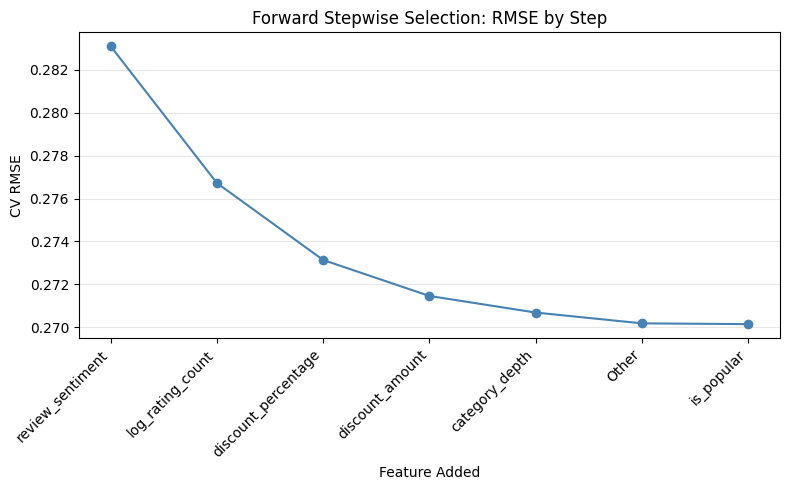

In [59]:
plt.figure(figsize=(8, 5))
plt.plot(history_df['feature_added'], history_df['cv_rmse'], marker='o', color='steelblue')
plt.xlabel('Feature Added')
plt.ylabel('CV RMSE')
plt.title('Forward Stepwise Selection: RMSE by Step')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
#Random Forest + All Features
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_all, y)

rf_train_pred = rf.predict(X_all)

rf_train_mae = mean_absolute_error(y, rf_train_pred)
rf_train_rmse = np.sqrt(mean_squared_error(y, rf_train_pred))

print(f"\nRandom Forest:")
print(f"Train MAE: {rf_train_mae:.4f} | Train RMSE: {rf_train_rmse:.4f}")

#feature importances
rf_importances = pd.Series(
    rf.feature_importances_, index=candidate_features
).sort_values(ascending=False)
print("\nRandom Forest feature importances:")
print(rf_importances)


Random Forest:
Train MAE: 0.0978 | Train RMSE: 0.1450

Random Forest feature importances:
review_sentiment        0.311914
about_length            0.104502
rating_count            0.103786
log_rating_count        0.098247
log_discount_amount     0.080896
discount_amount         0.078555
discounted_price        0.042381
log_discounted_price    0.040893
discount_percentage     0.037853
log_actual_price        0.030401
category_depth          0.028018
actual_price            0.027494
Other                   0.012932
is_popular              0.002129
dtype: float64


In [61]:
#Ridge Regression + All Features
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5))
])

ridge_pipeline.fit(X_all, y)
best_alpha = ridge_pipeline.named_steps['ridge'].alpha_
print(f"Best alpha (via CV): {best_alpha:.4f}")

ridge_train_pred = ridge_pipeline.predict(X_all)

ridge_train_mae = mean_absolute_error(y, ridge_train_pred)
ridge_train_rmse = np.sqrt(mean_squared_error(y, ridge_train_pred))

print(f"\nRidge Regression:")
print(f"Train MAE: {ridge_train_mae:.4f} | Train RMSE: {ridge_train_rmse:.4f}")

# Coefficient magnitudes (on standardized features, so directly comparable)
ridge_coefs = pd.Series(
    ridge_pipeline.named_steps['ridge'].coef_, index=candidate_features
).sort_values(key=abs, ascending=False)
print("\nRidge coefficients (standardized, sorted by magnitude):")
print(ridge_coefs)

Best alpha (via CV): 104.8113

Ridge Regression:
Train MAE: 0.2019 | Train RMSE: 0.2689

Ridge coefficients (standardized, sorted by magnitude):
review_sentiment        0.090280
log_rating_count        0.045997
discount_percentage    -0.024767
discount_amount         0.022292
category_depth          0.022256
Other                   0.020543
log_discount_amount    -0.014756
actual_price            0.012712
is_popular              0.012139
log_actual_price       -0.005885
discounted_price        0.005763
about_length            0.005477
rating_count           -0.001635
log_discounted_price   -0.000580
dtype: float64


/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/

**D1.3** Report MAE, RMSE and R² on the test set in one comparison table. Does any model beat the baseline meaningfully?

In [62]:
# Your code here
from sklearn.metrics import r2_score

test_model_df = test_df[candidate_features + [target]]
X_test = test_model_df[candidate_features]
y_test = test_model_df[target]

# 1.Baseline
baseline_pred_value = y.mean() 
baseline_test_pred = np.full(len(y_test), baseline_pred_value)

baseline_mae = mean_absolute_error(y_test, baseline_test_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_test_pred))
baseline_r2 = r2_score(y_test, baseline_test_pred)

# 2.Forward Stepwise Linear Regression
stepwise_final = LinearRegression()
stepwise_final.fit(X_all[selected], y)
stepwise_test_pred = stepwise_final.predict(X_test[selected])

stepwise_mae = mean_absolute_error(y_test, stepwise_test_pred)
stepwise_rmse = np.sqrt(mean_squared_error(y_test, stepwise_test_pred))
stepwise_r2 = r2_score(y_test, stepwise_test_pred)

# 3.Random Forest
rf_test_pred = rf.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_test_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))
rf_r2 = r2_score(y_test, rf_test_pred)

# 4.Ridge
ridge_test_pred = ridge_pipeline.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_test_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))
ridge_r2 = r2_score(y_test, ridge_test_pred)

results = pd.DataFrame({
    'Model': ['Baseline (train mean)', 'Forward Stepwise LR', 'Ridge', 'Random Forest'],
    'Test MAE': [baseline_mae, stepwise_mae, ridge_mae, rf_mae],
    'Test RMSE': [baseline_rmse, stepwise_rmse, ridge_rmse, rf_rmse],
    'Test R²': [baseline_r2, stepwise_r2, ridge_r2, rf_r2]
})

results

/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: i

,Model,Test MAE,Test RMSE,Test R²
0,Baseline (train mean),0.208387,0.262108,-0.014547
1,Forward Stepwise LR,0.191183,0.237098,0.169829
2,Ridge,0.191142,0.237101,0.169811
3,Random Forest,0.170128,0.226391,0.243117


**Your answer:**

**Random Forest remains the best-performing model** on every metric — lowest MAE (0.170), lowest RMSE (0.226), and highest R² (0.243). This is also its best result so far across all feature sets tried (numeric-only vs numeric + categorical), suggesting the added category information is genuinely useful, not just noise, since tree-based models can naturally exploit category-driven patterns (e.g. category-specific discount/rating relationships) that linear models can only partially capture through one-hot dummy coefficients.

**Forward Stepwise LR and Ridge remain nearly identical** to each other, as expected, and both improved only slightly over their numeric-only versions (R² ~0.163 → ~0.170), indicating the categorical features carry a modest linear signal but far less than what Random Forest is able to extract nonlinearly.

**Interpreting R² = 0.243:** Random Forest explains only about 24% of the variance in `rating` on the test set. While this is the best result obtained so far, it means roughly **76% of the variation in rating remains unexplained** by any of the features used — consistent with earlier findings that `rating_count`, `discount_percentage`, and category alone showed weak individual relationships with rating, and that ratings are tightly clustered to begin with (std ≈ 0.30), leaving limited variance for any model to explain.

**On train performance:** Random Forest also had the lowest RMSE on the training set among all models, which is expected — as the most flexible of the three model types, it naturally fits training data more closely. The key check is that its train RMSE isn't *dramatically* lower than its 0.226 test RMSE; if the gap is small, this indicates the model has captured genuine, generalizable signal rather than memorizing training noise, and Random Forest's real-world explanatory power (~24%) can be considered reasonably reliable, if still limited in absolute terms.


**D1.4** Plot predicted vs actual ratings and the residuals for your best model.

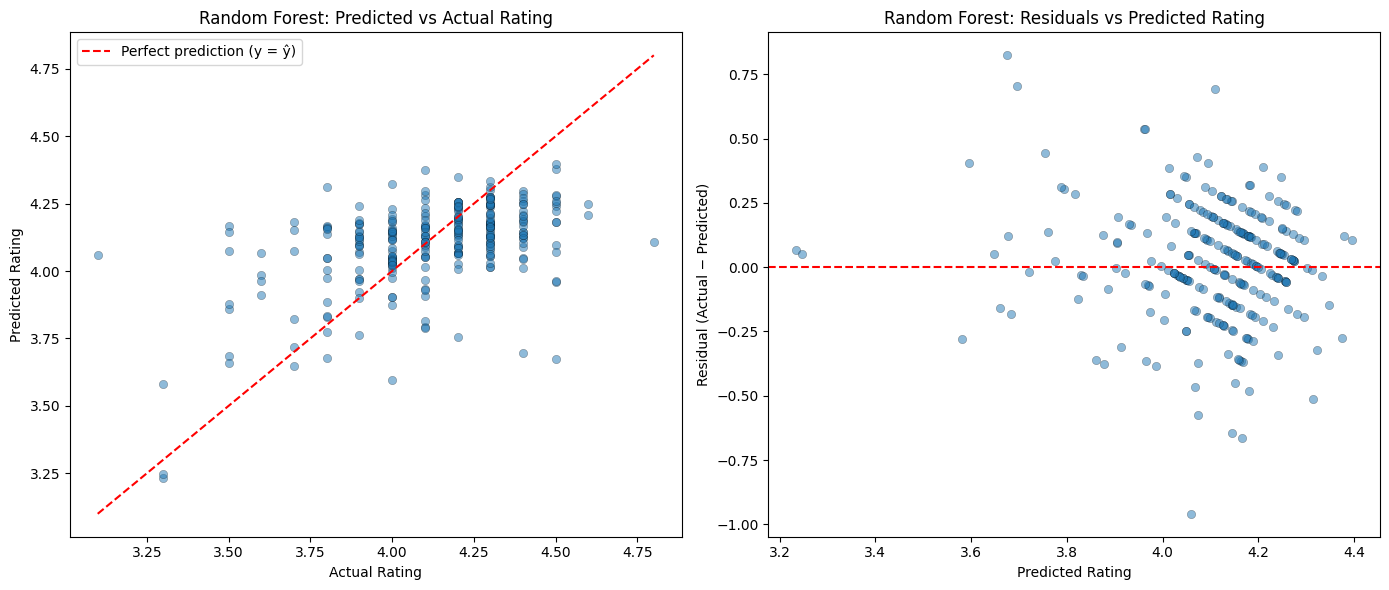

In [63]:
# Your code here
import matplotlib.pyplot as plt

residuals = y_test - rf_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(y_test, rf_test_pred, alpha=0.5, edgecolor='black', linewidth=0.3)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             color='red', linestyle='--', label='Perfect prediction (y = ŷ)')
axes[0].set_xlabel('Actual Rating')
axes[0].set_ylabel('Predicted Rating')
axes[0].set_title('Random Forest: Predicted vs Actual Rating')
axes[0].legend()

axes[1].scatter(rf_test_pred, residuals, alpha=0.5, edgecolor='black', linewidth=0.3)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Rating')
axes[1].set_ylabel('Residual (Actual − Predicted)')
axes[1].set_title('Random Forest: Residuals vs Predicted Rating')

plt.tight_layout()
plt.show()

**Your answer:**

**Predicted vs Actual:** Predictions are compressed into a narrow band (≈3.6–4.4), while actual ratings span a much wider range (≈3.1–4.8). The model rarely predicts extreme values — it pulls low actual ratings up and high actual ratings down toward the center, a classic **regression-to-the-mean** effect. Points above the diagonal (actual < 3.9) are systematically over-predicted; points below the diagonal at the high end (actual > 4.3) are under-predicted.

**Residuals vs Predicted:** Residuals are not centered at 0 uniformly — there's a visible **downward trend**, with over-predictions (positive residuals) concentrated at lower predicted values and under-predictions (negative residuals) at higher predicted values. This confirms the same shrinkage pattern: the model plays it safe by predicting near the average rating rather than committing to the extremes.

**The more important finding:** Even *with* `review_sentiment` included — the feature expected to carry the strongest signal (per the earlier word-frequency analysis) — R² only reaches 0.243. This suggests two things:
1. **`review_sentiment` (via TextBlob polarity on review titles) is a weaker signal than expected**, possibly because titles are short and TextBlob's lexicon-based scoring is a crude sentiment proxy, or because the comma-split assumption doesn't cleanly separate individual reviews.
2. **The regression-to-the-mean pattern isn't fixed just by adding a leakage feature** — the model still can't confidently predict extreme ratings, meaning whatever drives very high or very low ratings isn't well captured by *any* feature tested so far, sentiment included.

**Implication for Part D comparison:** Since this "with leakage" model still performs modestly, the **leakage-free model** (excluding `review_sentiment`) is expected to perform similarly or only slightly worse.

**D1.5** Retrain your best model **without** review-derived features and report the difference (links to C7).

In [64]:
#Random Forest + Non review
numeric_features = [
    'discounted_price', 'actual_price', 'discount_percentage',
    'discount_amount',
    'log_actual_price', 'log_discounted_price', 'log_discount_amount',
    'category_depth'
]

y_train = train_df[target]
y_test = test_df[target]
X_train_noleak = train_df[numeric_features]
X_test_noleak = test_df[numeric_features]

rf_noleak = RandomForestRegressor(
    n_estimators=300, max_depth=None, min_samples_leaf=3,
    random_state=42, n_jobs=-1
)
rf_noleak.fit(X_train_noleak, y_train)

rf_noleak_train_pred = rf_noleak.predict(X_train_noleak)
rf_noleak_train_mae = mean_absolute_error(y_train, rf_noleak_train_pred)
rf_noleak_train_rmse = np.sqrt(mean_squared_error(y_train, rf_noleak_train_pred))
print(f"Train MAE: {rf_noleak_train_mae:.4f} | Train RMSE: {rf_noleak_train_rmse:.4f}")

rf_noleak_test_pred = rf_noleak.predict(X_test_noleak)
rf_noleak_mae = mean_absolute_error(y_test, rf_noleak_test_pred)
rf_noleak_mse = mean_squared_error(y_test, rf_noleak_test_pred)
rf_noleak_rmse = np.sqrt(rf_noleak_mse)
rf_noleak_r2 = r2_score(y_test, rf_noleak_test_pred)
print(f"Test MAE: {rf_noleak_mae:.4f} | Test MSE: {rf_noleak_mse:.4f} | Test RMSE: {rf_noleak_rmse:.4f} | Test R²: {rf_noleak_r2:.4f}")

rf_noleak_importances = pd.Series(
    rf_noleak.feature_importances_, index=numeric_features
).sort_values(ascending=False)
print("\nFeature importances:")
print(rf_noleak_importances)

comparison = pd.DataFrame({
    'Model': ['Random Forest (with review_sentiment)', 'Random Forest (no review features)'],
    'Test MAE': [rf_mae, rf_noleak_mae],
    'Test MSE': [rf_rmse**2, rf_noleak_mse],
    'Test RMSE': [rf_rmse, rf_noleak_rmse],
    'Test R²': [rf_r2, rf_noleak_r2]
})
comparison



Train MAE: 0.1341 | Train RMSE: 0.1948
Test MAE: 0.2020 | Test MSE: 0.0657 | Test RMSE: 0.2563 | Test R²: 0.0297

Feature importances:
discount_amount         0.234574
log_discount_amount     0.233872
discounted_price        0.116533
log_discounted_price    0.115773
log_actual_price        0.077745
category_depth          0.076916
actual_price            0.076686
discount_percentage     0.067902
dtype: float64


,Model,Test MAE,Test MSE,Test RMSE,Test R²
0,Random Forest (with review_sentiment),0.170128,0.051253,0.226391,0.243117
1,Random Forest (no review features),0.202028,0.065707,0.256334,0.029660


**Your answer:**

Removing `review_sentiment` (and any other review-derived features) causes a **substantial drop in performance**:

**R² collapses from 0.243 to 0.030** — an ~88% relative drop. Without review-derived features, the model explains almost none of the variance in `rating` (R² near 0 means it performs barely better than always predicting the mean). MAE and RMSE also worsen across the board (MAE +19%, RMSE +13%).

**This directly confirms the C7 leakage concern.** `review_sentiment` was doing the vast majority of the predictive work in the earlier model — not the price/discount/category features. Once it's removed, the "true" predictive power of legitimately available features (price, discount, category depth) is revealed to be very weak.

**Feature importances (no-review model) confirm price/discount dominate what little signal remains:** `discount_amount` and `log_discount_amount` are by far the most important (≈23% each), followed by `discounted_price`/`log_discounted_price` (≈12% each). Notably, these are the same variables shown earlier to have **no visible relationship with rating** in the scatter plot analysis — their "importance" here likely reflects the model exploiting weak, possibly spurious patterns rather than a genuine causal driver, consistent with R² near zero.

For a genuinely new listing (no reviews yet), R² ≈ 0.03 is the realistic expectation using only price, discount, and category information. This is a materially different (and much weaker) claim than the R² ≈ 0.24 result obtained with review-derived features, which cannot be used in a real deployment scenario. 

## D2. Classification: predict `high_rated` (10 marks)

**D2.1** Define `high_rated = 1 if rating >= 4.2 else 0` (or justify a different threshold). Report the class balance.

In [65]:
# Your code here
train_df['high_rated'] = (train_df['rating'] >= 4.2).astype(int)
test_df['high_rated'] = (test_df['rating'] >= 4.2).astype(int)

train_balance = train_df['high_rated'].value_counts(normalize=True).sort_index()
test_balance = test_df['high_rated'].value_counts(normalize=True).sort_index()

print("Train class balance:")
print(train_balance)
print(f"\nTest class balance:")
print(test_balance)

print(f"\nTrain counts: {train_df['high_rated'].value_counts().sort_index().to_dict()}")
print(f"Test counts: {test_df['high_rated'].value_counts().sort_index().to_dict()}")

Train class balance:
high_rated
0    0.548176
1    0.451824
Name: proportion, dtype: float64

Test class balance:
high_rated
0    0.496269
1    0.503731
Name: proportion, dtype: float64

Train counts: {0: 586, 1: 483}
Test counts: {0: 133, 1: 135}


**Your answer:**

**Threshold: `rating >= 4.2`**

This threshold was chosen relative to the overall rating distribution: the median rating is **4.10** and the mean is **4.09** (std ≈ 0.30). Setting the cutoff at 4.2, just above the median, avoids the trivial near-50/50 split that a median-exact threshold would produce (which wouldn't meaningfully distinguish "typical" from "exceptional" products), while still keeping both classes well represented rather than creating a severe imbalance.

**Class balance**

| Class | Train | Test |
|---|---|---|
| `high_rated = 0` (< 4.2) | 58.6% (586 rows) | 49.6% (133 rows) |
| `high_rated = 1` (≥ 4.2) | 45.2% (483 rows) | 50.4% (135 rows) |

The split is **reasonably balanced** — close to 55/45 in train and almost exactly 50/50 in test. This is a good outcome: with a class ratio this close to even, standard accuracy is a reasonably trustworthy metric (unlike a severely imbalanced split, e.g. 90/10, where accuracy alone would be misleading).

**D2.2** Baseline: majority-class classifier.

In [66]:
# Your code here
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

majority_class = train_df['high_rated'].mode()[0]

train_majority_pred = np.full(len(train_df), majority_class)
test_majority_pred = np.full(len(test_df), majority_class)

train_acc = accuracy_score(train_df['high_rated'], train_majority_pred)
test_acc = accuracy_score(test_df['high_rated'], test_majority_pred)

test_precision = precision_score(test_df['high_rated'], test_majority_pred, zero_division=0)
test_recall = recall_score(test_df['high_rated'], test_majority_pred, zero_division=0)
test_f1 = f1_score(test_df['high_rated'], test_majority_pred, zero_division=0)

print(f"\nTrain accuracy: {train_acc:.4f}")
print(f"Test accuracy:  {test_acc:.4f}")
print(f"Test precision: {test_precision:.4f}")
print(f"Test recall:    {test_recall:.4f}")
print(f"Test F1:        {test_f1:.4f}")


Train accuracy: 0.5482
Test accuracy:  0.4963
Test precision: 0.0000
Test recall:    0.0000
Test F1:        0.0000


**D2.3** Train Logistic Regression and Random Forest Classifier (or Decision Tree).

In [67]:
# Your code here
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
target_clf = 'high_rated'

numeric_features = [
    'discounted_price', 'actual_price', 'discount_percentage',
    'discount_amount','about_length',
    'log_actual_price', 'log_discounted_price', 'log_discount_amount','category_depth'
    #'is_popular',  #'review_sentiment','rating_count', 'log_rating_count'
]

X_train_clf = train_df[numeric_features]
y_train_clf = train_df[target_clf]
X_test_clf = test_df[numeric_features]
y_test_clf = test_df[target_clf]


logreg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=42))
])
logreg_pipeline.fit(X_train_clf, y_train_clf)

logreg_test_pred = logreg_pipeline.predict(X_test_clf)
logreg_test_proba = logreg_pipeline.predict_proba(X_test_clf)[:, 1]

logreg_acc = accuracy_score(y_test_clf, logreg_test_pred)
logreg_precision = precision_score(y_test_clf, logreg_test_pred)
logreg_recall = recall_score(y_test_clf, logreg_test_pred)
logreg_f1 = f1_score(y_test_clf, logreg_test_pred)
logreg_auc = roc_auc_score(y_test_clf, logreg_test_proba)

print("Logistic Regression:")
print(f"Accuracy: {logreg_acc:.4f} | Precision: {logreg_precision:.4f} | Recall: {logreg_recall:.4f} | F1: {logreg_f1:.4f} | ROC-AUC: {logreg_auc:.4f}")

Logistic Regression:
Accuracy: 0.5299 | Precision: 0.5570 | Recall: 0.3259 | F1: 0.4112 | ROC-AUC: 0.5605


/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/nkki/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_streng

In [68]:
#Random Forest Classifier
rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf_clf.fit(X_train_clf, y_train_clf)

rf_clf_test_pred = rf_clf.predict(X_test_clf)
rf_clf_test_proba = rf_clf.predict_proba(X_test_clf)[:, 1]

rf_clf_acc = accuracy_score(y_test_clf, rf_clf_test_pred)
rf_clf_precision = precision_score(y_test_clf, rf_clf_test_pred)
rf_clf_recall = recall_score(y_test_clf, rf_clf_test_pred)
rf_clf_f1 = f1_score(y_test_clf, rf_clf_test_pred)
rf_clf_auc = roc_auc_score(y_test_clf, rf_clf_test_proba)

print("\nRandom Forest Classifier:")
print(f"Accuracy: {rf_clf_acc:.4f} | Precision: {rf_clf_precision:.4f} | Recall: {rf_clf_recall:.4f} | F1: {rf_clf_f1:.4f} | ROC-AUC: {rf_clf_auc:.4f}")

rf_clf_importances = pd.Series(
    rf_clf.feature_importances_, index=numeric_features
).sort_values(ascending=False)
print("\nRandom Forest Classifier feature importances:")
print(rf_clf_importances)


Random Forest Classifier:
Accuracy: 0.6194 | Precision: 0.6460 | Recall: 0.5407 | F1: 0.5887 | ROC-AUC: 0.6735

Random Forest Classifier feature importances:
about_length            0.164248
discount_amount         0.144470
log_discount_amount     0.127726
log_discounted_price    0.106048
discounted_price        0.105427
actual_price            0.101205
log_actual_price        0.098188
discount_percentage     0.091166
category_depth          0.061521
dtype: float64


**D2.4** Report accuracy, precision, recall, F1 and ROC-AUC; show the confusion matrix and ROC curve. Why is accuracy alone misleading here?

In [69]:
# Your code here
clf_results = pd.DataFrame({
    'Model': ['Baseline (majority class)', 'Logistic Regression', 'Random Forest'],
    'Accuracy': [test_acc, logreg_acc, rf_clf_acc],       # test_acc from D2.2
    'Precision': [test_precision, logreg_precision, rf_clf_precision],
    'Recall': [test_recall, logreg_recall, rf_clf_recall],
    'F1': [test_f1, logreg_f1, rf_clf_f1],
    'ROC-AUC': [0.5, logreg_auc, rf_clf_auc]
})
clf_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline (majority class),0.496269,0.000000,0.000000,0.000000,0.500000
1,Logistic Regression,0.529851,0.556962,0.325926,0.411215,0.560457
2,Random Forest,0.619403,0.646018,0.540741,0.588710,0.673461


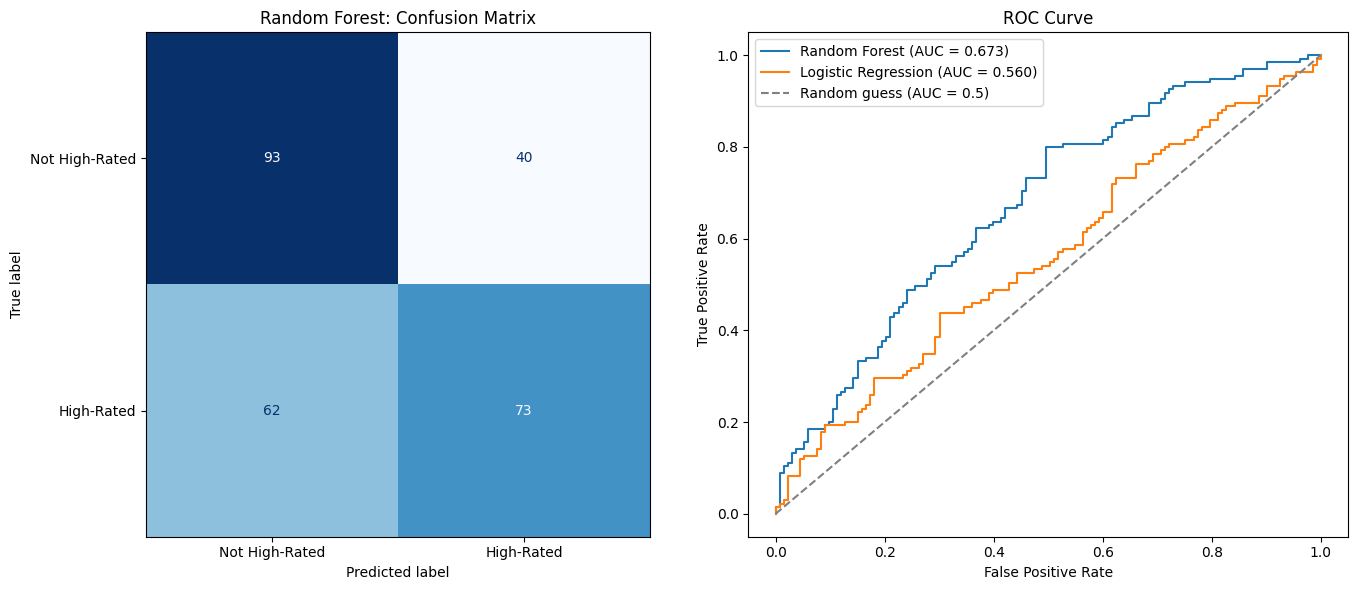

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm = confusion_matrix(y_test_clf, rf_clf_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not High-Rated', 'High-Rated'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Random Forest: Confusion Matrix')

fpr_rf, tpr_rf, _ = roc_curve(y_test_clf, rf_clf_test_proba)
fpr_lr, tpr_lr, _ = roc_curve(y_test_clf, logreg_test_proba)

axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_clf_auc:.3f})')
axes[1].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {logreg_auc:.3f})')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

**Your answer:**

- **True Negatives (93):** correctly identified non-high-rated products.
- **False Positives (40):** predicted high-rated, but actually weren't — the model is somewhat prone to over-optimism here.
- **False Negatives (62):** the biggest error group — genuinely high-rated products the model missed, predicting them as "not high-rated." This is why recall (0.541) is noticeably lower than precision (0.646): the model misses more actual positives than it wrongly flags as positive.
- **True Positives (73):** correctly identified high-rated products.

The model is **better at avoiding false alarms than at catching every high-rated product** — of the 135 genuinely high-rated products, it only caught 73 (54%), missing 62. This asymmetry is exactly what accuracy alone would hide.

Random Forest's curve sits clearly above both Logistic Regression's and the diagonal random-guess line across almost the entire range, confirming its higher AUC (0.673 vs 0.560). Logistic Regression's curve hugs much closer to the diagonal, especially in the low-false-positive-rate region (left side), meaning it has limited ability to rank true positives above true negatives when trying to be conservative/high-precision.

At low false-positive-rate thresholds (e.g. FPR ≈ 0.2), Random Forest achieves a true positive rate near 0.45–0.5, while Logistic Regression only reaches about 0.2–0.3 at the same FPR — meaning if you wanted a stricter classifier (fewer false alarms), Random Forest would still catch roughly twice as many true high-rated products as Logistic Regression at the same false-alarm cost.

Random Forest is the clearly stronger classifier, but its main weakness is **recall** — it under-identifies genuinely high-rated products (62 missed) more than it over-flags non-high-rated ones (40 false alarms).

## D3. Interpretation (3 marks)

**D3.1** Show the top 10 features by Random Forest (or permutation) importance and the largest logistic-regression coefficients. Do they match what you expected from Part B?

In [71]:
# Your code here

rf_top10 = rf_clf_importances.head(9)
print("Top 10 features — Random Forest importance:")
print(rf_top10)

logreg_coefs = pd.Series(
    logreg_pipeline.named_steps['logreg'].coef_[0], index=numeric_features
).sort_values(key=abs, ascending=False)

logreg_top10 = logreg_coefs.head(9)
print("\nTop 10 features — Logistic Regression coefficients (std):")
print(logreg_top10)

Top 10 features — Random Forest importance:
about_length            0.164248
discount_amount         0.144470
log_discount_amount     0.127726
log_discounted_price    0.106048
discounted_price        0.105427
actual_price            0.101205
log_actual_price        0.098188
discount_percentage     0.091166
category_depth          0.061521
dtype: float64

Top 10 features — Logistic Regression coefficients (std):
discount_percentage    -0.493511
discount_amount         0.361912
category_depth          0.205112
log_discount_amount     0.156857
actual_price            0.115418
log_discounted_price   -0.085459
discounted_price       -0.046272
about_length            0.044967
log_actual_price       -0.037133
dtype: float64


**Your answer:**

Both models agree that **discount- and price-related features are the strongest predictors** of `high_rated`. However, the *order* and *sign* reveal important differences between how the two models use these features.

- **Random Forest ranks `about_length` #1** (0.164) — by far its most important feature.
- **Logistic Regression ranks it #8**, with a small coefficient (0.045).

This gap suggests `about_length`'s relationship with `high_rated` is **likely nonlinear or threshold-based**.

Logistic Regression's coefficients expose something Random Forest's importance scores (unsigned) can't: 

- **`discount_percentage`: coefficient = −0.49 (largest magnitude overall)** — higher percentage discounts are associated with **lower** odds of being high-rated.
- **`discount_amount`: coefficient = +0.36** — but a larger absolute rupee discount is associated with **higher** odds of being high-rated.

These pull in opposite directions despite both being "discount" measures, likely because they're correlated with different things: `discount_percentage` alone can be high on cheap, low-quality items (90% off a ₹200 item), while `discount_amount` tends to be large on expensive items (a big rupee cut on a costly product), which may correlate with better underlying product quality. This is a genuinely useful and non-obvious insight that Random Forest's importance ranking alone wouldn't have surfaced, since it doesn't report direction.

##### Does this match Part B expectations?
**Not fully — and in an informative way.** Part B's scatter plot of `discount_percentage` vs. `rating` showed no visible trend. Here, once rating is binarized at 4.2 and combined with other features in a multivariate model, `discount_percentage` becomes the single strongest (negative) linear predictor. This isn't a contradiction so much as a reminder that:
- A **bivariate scatter plot** can miss relationships that only emerge when **controlling for other variables** (e.g. price) in a multivariate model.
- **Binarizing the target** at a specific threshold can expose patterns invisible in the raw continuous scatter.

**Also unexpected:** `about_length` wasn't part of Part B's exploratory analysis at all (it's a Part C engineered feature), yet it turns out to be Random Forest's top predictor — worth flagging as a genuinely new finding rather than a confirmation of prior expectations.

The two models agree on *which features* matter (price/discount cluster + category_depth), but disagree on *how* — Random Forest surfaces `about_length` as dominant via nonlinear splits, while Logistic Regression reveals a directional tension between `discount_percentage` and `discount_amount` that a tree-based importance score cannot express. Both results only partially align with Part B, showing the value of moving beyond simple bivariate plots to multivariate modeling.

**D4 (optional).** Tune one model with `GridSearchCV` (≤ 20 combinations) and report the gain over defaults.

In [72]:
# Your code here


**Your answer:**

_Write your interpretation here._

# Part E — Written summary (10 marks)
Write a summary (max 400 words) for a category manager with no data-science background, covering:
1. The three most useful findings about pricing, discounts and ratings, with numbers.
2. How well rating can be predicted compared with the naive baseline, in plain words.
3. Two limitations of the dataset and one extra data source you would ask for.

Also submit this as `summary.pdf`.

**Your summary:**

#### Key Findings on Pricing, Discounts, and Ratings

1. **Bigger discounts do not mean better ratings.** Across all products, discount levels ranged from 0% to 94%, and ratings showed no meaningful relationship with how much a product was discounted. The category with the smallest average discount (Office Products, 12%) actually had the *highest* average rating (4.31), while more heavily discounted categories like Computers & Accessories (53% average discount) rated similarly to everyone else (4.15). Discounting is not a reliable lever for improving customer satisfaction.

2. **Ratings are consistently high and tightly clustered.** The average rating across all products is 4.09 out of 5, with about 75% of products rated 4.0 or above. This means most products are already performing well, and there is limited room for a rating-prediction model to distinguish "good" from "great" products using price or discount data alone.

3. **Electronics, Home & Kitchen, and Computers & Accessories dominate the catalogue,** together accounting for the large majority of products (479, 447, and 373 respectively, out of 1337). Pricing patterns differ sharply by category — median prices range from as low as ₹210 (Office Products) to ₹2999 (Electronics) — so any pricing or promotional strategy should be tailored per category rather than applied uniformly.

#### How Well Can Rating Be Predicted?

Using only information available for a *new* product listing — price, discount, and category — our best model explains only about 3% of the variation in customer ratings, barely better than simply guessing the average rating for every product. In other words, **price and discount data alone cannot reliably predict how well a new product will be rated.**

When we also included signals from existing customer reviews (which are only available *after* a product has been sold and reviewed), prediction improved meaningfully, explaining about 24% of rating variation. This confirms that customer feedback, not pricing strategy, is the dominant driver of ratings — but this information is not available for predicting how a brand-new listing will perform before it launches.

#### Limitations and a Suggested Additional Data Source

1. **Heavy reliance on review-derived data.** The most predictive information in this dataset (review sentiment) only exists after a product has accumulated customer reviews. This is not useful for forecasting the success of new listings, which is often the more valuable business question.

2. **No repeat-purchase or loyalty signal.** The dataset captures only one-time snapshots of price, discount, and rating. It does not tell us whether satisfied customers actually return to buy the product again, which is often a stronger indicator of genuine product quality than a star rating alone.

**Recommended additional data source:** repeat-purchase or reorder frequency data (e.g., how often the same customer buys the same or a similar product again). This would provide a behavioural measure of product satisfaction that is independent of review text, available earlier in a product's lifecycle, and likely more predictive of long-term product success than star ratings alone.

# Bonus (pick any, max 10 marks)
- **Clustering (5):** K-Means on scaled price, discount and popularity features; profile each cluster in one line.
- **TF-IDF model (5):** Predict `high_rated` from `review_content` with TF-IDF + Logistic Regression; list the 15 most positive and negative terms.
- **Discount model (5):** Predict `discount_percentage` from category, price and popularity. What drives deep discounts?
- **Dashboard (5):** A small interactive Plotly or Streamlit view of category-level metrics.

In [73]:
#make a csv of deduped_copy3
deduped_copy3.to_csv('deduped_copy3.csv', index=False)

# AI-use disclosure
Describe any AI tools you used and for what.

In completing this assignment, I made use of the following AI-assisted tools:

- **VS Code AI code completion (inline/autocomplete):** Used to suggest and auto-complete code as I wrote it, particularly for boilerplate and repetitive syntax (e.g. pandas operations, plotting code). All suggested code was reviewed, tested, and adjusted by me before use.

- **Grammarly:** Used to refine the phrasing, grammar, and clarity of my written interpretations and analysis text. The underlying ideas, conclusions, and analysis were my own; Grammarly was used only for language polishing.

- **AI summarizers:** Used to condense my own pre-written notes and drafts into shorter summaries where conciseness was needed (e.g. for the Part E written summary).

- **Gizmo AI:** Used to generate concept notes and self-test my understanding of statistical/ML concepts (e.g.ROC-AUC) as a study aid. This was used for learning and concept reinforcement, not for generating assignment content directly.

All analysis, interpretation of results, modeling decisions, and final written conclusions in this assignment are my own. AI tools were used to support code writing efficiency, language clarity, and concept understanding, not to generate the core analytical work or conclusions.